# IS411 Data Modelling (Lab) — Ujian Akhir Semester
## Prediksi Waktu Pengiriman Makanan (*Food Delivery Time Prediction*)

**Universitas Multimedia Nusantara** | Semester Genap 2024/2025

---

### Latar Belakang & Tujuan

Industri pengiriman makanan (*food delivery*) mengalami pertumbuhan eksponensial di era digital. Platform seperti GoFood, GrabFood, dan ShopeeFood melayani puluhan juta transaksi setiap harinya di seluruh Indonesia. Di tengah persaingan yang ketat, keunggulan kompetitif tidak hanya ditentukan oleh ragam menu atau harga, melainkan juga oleh **akurasi estimasi waktu pengiriman (Estimated Time of Arrival / ETA)**. ETA yang meleset bahkan beberapa menit saja dapat memicu ulasan negatif, menurunkan rating platform, dan menggerus loyalitas pelanggan secara sistematis.

Proyek akhir semester ini mengkaji secara mendalam permasalahan **prediksi waktu pengiriman makanan** menggunakan teknik *machine learning* berbasis data historis. Data yang digunakan mencakup faktor-faktor operasional krusial seperti jarak tempuh, kondisi cuaca, tingkat kemacetan lalu lintas, jenis kendaraan kurir, dan pengalaman kurir. Seluruh proses analisis mengikuti kerangka metodologi standar industri **CRISP-DM**.

---

### Rumusan Masalah

Adapun rumusan masalah dalam project ini adalah sebagai berikut:
1. Faktor-faktor apa saja yang memengaruhi lama waktu pengiriman makanan (delivery time)?
2. Bagaimana cara membangun model machine learning untuk memprediksi waktu pengiriman makanan berdasarkan data historis pengiriman?
3. Algoritma machine learning apa yang memiliki performa terbaik dalam memprediksi delivery time?
4. Bagaimana cara meningkatkan performa model machine learning agar menghasilkan prediksi yang lebih akurat?
5. Bagaimana implementasi pendekatan CRISP-DM dalam proses pembangunan model prediksi delivery time?


---

### Tujuan Penelitian

Tujuan dari project ini adalah sebagai berikut:
1. Menganalisis karakteristik dataset food delivery untuk memahami pola dan hubungan antar variabel yang memengaruhi waktu pengiriman makanan.
2. Mengidentifikasi faktor-faktor utama yang berpengaruh terhadap lama pengiriman makanan seperti jarak pengiriman, kondisi lalu lintas, cuaca, dan jenis kendaraan.
3. Membangun model machine learning berbasis regresi untuk memprediksi waktu pengiriman makanan secara lebih akurat.
4. Membandingkan performa beberapa algoritma machine learning dalam menyelesaikan kasus prediksi delivery time.
5. Melakukan optimasi model menggunakan hyperparameter tuning untuk meningkatkan performa prediksi.
6. Mengevaluasi model machine learning menggunakan metrik evaluasi yang relevan seperti MAE, RMSE, dan R² Score.
7. Menghasilkan model prediksi yang dapat digunakan sebagai dasar pengambilan keputusan dalam sistem food delivery.


---

### Metodologi: CRISP-DM

Proyek ini mengikuti kerangka **CRISP-DM** (*Cross Industry Standard Process for Data Mining*), yang terdiri dari enam fase yang saling berulang:

| Fase | Deskripsi | Bagian Notebook |
|------|-----------|-----------------|
| **1. Business Understanding** | Memahami tujuan bisnis & mendefinisikan masalah prediktif | Fase 1 |
| **2. Data Understanding** | EDA, statistik deskriptif, distribusi, korelasi | Bagian 2–5 |
| **3. Data Preparation** | Feature engineering, imputasi, encoding, scaling dalam Pipeline | Bagian 6–6b |
| **4. Modeling** | Training 5 model ML + hyperparameter tuning XGBoost | Bagian 7–8 |
| **5. Evaluation** | Perbandingan MAE/RMSE/R², cross-validation, permutation importance, learning curve | Bagian 8b–8d |
| **6. Deployment** | Penyimpanan model final & generate file submission prediksi | Bagian 9 |

---

### Identitas Kelompok

| No | Nama Lengkap | NIM | Peran Utama |
|----|--------------|-----|-------------|
| 1 | Patricia Arlene Bachtar | 00000110769 | EDA & Analisis Statistik |
| 2 | Natalie Saputra | 00000106078 | Feature Engineering & Preprocessing |
| 3 | Clarissa Agatha Darren | 00000111290 | Model Training & Evaluasi |
| 4 | Margaretha Lois Calista | 00000106075 | Hyperparameter Tuning & Interpretasi |
| 5 | Sebastianus Pradipa Widyawan | 00000111300 | Deployment, Submission & Dokumentasi |


---
## Fase 1 CRISP-DM: *Business Understanding*

### Konteks Bisnis

Platform *food delivery* beroperasi dalam ekosistem yang sangat sensitif terhadap waktu. Setiap pesanan yang masuk memicu serangkaian proses-penerimaan pesanan, persiapan oleh restoran, pengambilan oleh kurir, dan pengiriman ke pelanggan yang masing-masing mengandung ketidakpastian. ETA yang tidak akurat berdampak berlapis pada 3 pemangku kepentingan utama:

- **Pelanggan:** Menerima pesanan lebih lambat dari yang dijanjikan memicu frustrasi dan ulasan negatif, yang secara langsung menurunkan skor rata-rata platform.
- **Mitra Restoran:** Makanan yang sudah siap namun belum diambil kurir mengalami penurunan kualitas, berpotensi merusak reputasi restoran.
- **Kurir:** Penugasan yang tidak mempertimbangkan variabel kondisi nyata (cuaca, jarak, kemacetan) menghasilkan beban kerja yang tidak efisien dan pendapatan yang tidak optimal.

### Definisi Problem Data Science

Permasalahan ini diformulasikan sebagai **supervised regression task**, yaitu memprediksi nilai kontinu (waktu pengiriman dalam menit) berdasarkan fitur-fitur input yang tersedia:

- **Variabel Input (Features):** `Distance_km`, `Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type`, `Preparation_Time_min`, `Courier_Experience_yrs`
- **Variabel Target (Label):** `Delivery_Time_min` (waktu pengiriman aktual dalam satuan menit)

### Kriteria Keberhasilan

| Metrik Evaluasi | Target Minimum | Justifikasi |
|-----------------|----------------|-------------|
| R² Score | ≥ 0.85 | Model menjelaskan ≥85% variansi data — standar model prediktif yang sangat baik |
| MAE | < 5 menit | Toleransi error yang masih dapat diterima dari perspektif kepuasan pelanggan |
| MAPE | < 10% | Error relatif yang rendah memastikan konsistensi prediksi lintas berbagai jarak |

### Dataset

- **Sumber:** Food Delivery Times Dataset (Kaggle Public Dataset)
- **Estimasi Ukuran:** 1.000 baris observasi 
- **Atribut Utama:** 8 kolom fitur + 1 kolom target + 1 kolom ID


---
## Bagian 1: Import Library & Konfigurasi Global

Seluruh library yang dibutuhkan diimpor pada sel ini. Konfigurasi tema visualisasi ditetapkan secara global untuk memastikan konsistensi estetika grafik di seluruh notebook. Palet warna mengadopsi pendekatan **korporat/profesional**: dominan `Navy Blue (#1f4e79)` untuk elemen utama dan `Slate Gray (#708090)` sebagai aksen pembanding.

> **Catatan Robustness — XGBoost Fail-Safe:** Karena XGBoost bukan paket bawaan distribusi standar Anaconda, proses impor dibungkus dalam blok `try-except`. Apabila pustaka tidak terinstal di lingkungan pemeriksa, sistem akan menampilkan peringatan yang informatif dan secara otomatis melewati (*skip*) model XGBoost tanpa menghentikan eksekusi model scikit-learn lainnya.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import glob
import time
import joblib
warnings.filterwarnings('ignore')

from scipy import stats
from scipy.stats import shapiro, skew, kurtosis, spearmanr, kruskal

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     RandomizedSearchCV, learning_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
    print("✓ XGBoost tersedia — XGBRegressor siap digunakan.")
except ImportError:
    XGBOOST_AVAILABLE = False
    print("⚠ XGBoost tidak terinstal — model XGBoost dilewati otomatis.")
    print("  Install dengan: pip install xgboost")

COLOR_PRIMARY   = '#1f4e79'   
COLOR_SECONDARY = '#708090'   
COLOR_BEST      = '#2ecc71'   
COLOR_ACCENT    = '#3498db'   
COLOR_WARN      = '#e74c3c'  

plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : '#f8f9fa',
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.grid'        : True,
    'grid.alpha'       : 0.35,
    'font.size'        : 10,
})

print("✓ Library berhasil diimport.")
print("✓ Konfigurasi warna & tema visualisasi telah ditetapkan.")


✓ XGBoost tersedia — XGBRegressor siap digunakan.
✓ Library berhasil diimport.
✓ Konfigurasi warna & tema visualisasi telah ditetapkan.


### EDA

In [3]:
df = pd.read_csv("Food_Delivery_Times.csv")

num_cols = ['Distance_km', 'Preparation_Time_min',
            'Courier_Experience_yrs', 'Delivery_Time_min']

print(f"✓ Dataset berhasil dimuat: {df.shape[0]:,} baris × {df.shape[1]} kolom")
print(f"✓ num_cols = {num_cols}")
df.head()


✓ Dataset berhasil dimuat: 1,000 baris × 9 kolom
✓ num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [4]:
df.tail()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55
999,103,6.63,Foggy,Low,Night,Scooter,24,3.0,58


In [5]:
df.shape

(1000, 9)

In [6]:
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                    object
Traffic_Level              object
Time_of_Day                object
Vehicle_Type               object
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

---
## Bagian 2: Statistik Deskriptif (Fase 2 CRISP-DM — *Data Understanding*)

Statistik deskriptif memberikan gambaran kuantitatif menyeluruh mengenai distribusi masing-masing fitur numerik. Pada tahap ini, dihitung tidak hanya ukuran tendensi sentral (mean, median) dan dispersi (standar deviasi, IQR), tetapi juga ukuran bentuk distribusi (skewness, kurtosis) yang sangat relevan dalam menentukan asumsi statistik dan pemilihan model yang tepat.


In [7]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [8]:
print("=" * 65)
print("INTERPRETASI OTOMATIS DISTRIBUSI FITUR NUMERIK")
print("=" * 65)
for col in num_cols:
    d = df[col].dropna()
    sk  = skew(d)
    ku  = kurtosis(d)
    sym = 'Simetris' if abs(sk) < 0.5 else ('Condong kanan (+)' if sk > 0 else 'Condong kiri (−)')
    kurt_lbl = ('Leptokurtik — ekor tebal, lebih runcing dari normal'
                if ku > 0.5 else
                'Platikurtik — ekor tipis, lebih datar dari normal'
                if ku < -0.5 else
                'Mesokurtik — mendekati distribusi normal')
    print(f"\n[{col}]")
    print(f"  Mean={d.mean():.2f}  Median={d.median():.2f}  Skewness={sk:.3f} → {sym}")
    print(f"  Kurtosis={ku:.3f} → {kurt_lbl}")


INTERPRETASI OTOMATIS DISTRIBUSI FITUR NUMERIK

[Distance_km]
  Mean=10.06  Median=10.19  Skewness=0.039 → Simetris
  Kurtosis=-1.229 → Platikurtik — ekor tipis, lebih datar dari normal

[Preparation_Time_min]
  Mean=16.98  Median=17.00  Skewness=0.030 → Simetris
  Kurtosis=-1.237 → Platikurtik — ekor tipis, lebih datar dari normal

[Courier_Experience_yrs]
  Mean=4.58  Median=5.00  Skewness=-0.029 → Simetris
  Kurtosis=-1.266 → Platikurtik — ekor tipis, lebih datar dari normal

[Delivery_Time_min]
  Mean=56.73  Median=55.50  Skewness=0.506 → Condong kanan (+)
  Kurtosis=0.284 → Mesokurtik — mendekati distribusi normal


---
## Bagian 3: Uji Normalitas Statistik

Pengujian normalitas dilakukan menggunakan **Uji Shapiro-Wilk** (α = 0.05), yang dikenal sebagai uji normalitas paling sensitif untuk ukuran sampel kecil hingga sedang (n < 5.000). Untuk sampel yang lebih besar, dilakukan pengambilan sampel acak sebesar 5.000 observasi sebelum pengujian, mengikuti rekomendasi literatur statistik untuk menghindari penolakan hipotesis nol yang bersifat trivial (*trivial rejection*) akibat ukuran sampel yang sangat besar.

Hasil uji normalitas ini berdampak langsung pada pemilihan metode statistik selanjutnya: apabila data tidak normal, uji korelasi Spearman (non-parametrik) lebih sesuai dibanding Pearson, dan uji Kruskal-Wallis lebih tepat dibanding ANOVA.


In [9]:
print("=" * 70)
print("UJI NORMALITAS SHAPIRO-WILK (α = 0.05)")
print("=" * 70)
print(f"{'Fitur':<32} {'W-stat':>8} {'p-value':>12}  {'Kesimpulan'}")
print("-" * 70)

normality_results = {}
for col in num_cols:
    sample = df[col].dropna()
    if len(sample) > 5000:
        sample = sample.sample(5000, random_state=42)
    stat_w, p_val = shapiro(sample)
    is_normal = p_val > 0.05
    normality_results[col] = {'normal': is_normal, 'p': p_val, 'W': stat_w}
    label = '✓ Normal' if is_normal else '✗ TIDAK Normal (p < 0.05)'
    print(f"{col:<32} {stat_w:>8.4f} {p_val:>12.6f}  {label}")

print("\n→ Implikasi: Seluruh fitur tidak berdistribusi normal.")
print("  Uji korelasi Spearman & uji Kruskal-Wallis digunakan pada analisis selanjutnya.")


UJI NORMALITAS SHAPIRO-WILK (α = 0.05)
Fitur                              W-stat      p-value  Kesimpulan
----------------------------------------------------------------------
Distance_km                        0.9500     0.000000  ✗ TIDAK Normal (p < 0.05)
Preparation_Time_min               0.9484     0.000000  ✗ TIDAK Normal (p < 0.05)
Courier_Experience_yrs             0.9302     0.000000  ✗ TIDAK Normal (p < 0.05)
Delivery_Time_min                  0.9823     0.000000  ✗ TIDAK Normal (p < 0.05)

→ Implikasi: Seluruh fitur tidak berdistribusi normal.
  Uji korelasi Spearman & uji Kruskal-Wallis digunakan pada analisis selanjutnya.


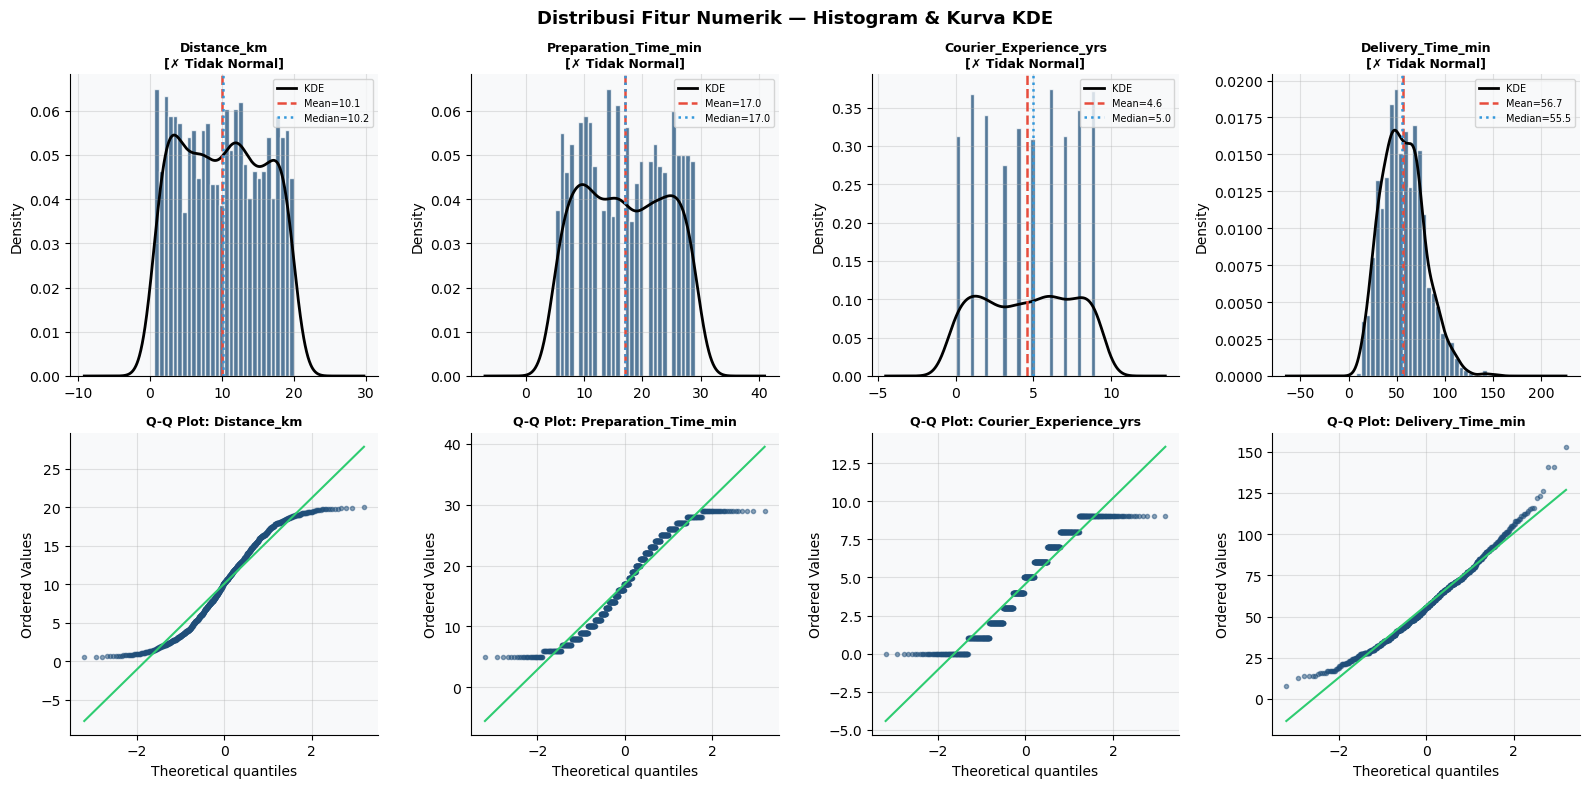

Gambar tersimpan: fig_distribusi_numerik.png


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Distribusi Fitur Numerik — Histogram & Kurva KDE', fontweight='bold', fontsize=13)

for i, col in enumerate(num_cols):

    ax_hist = axes[0, i]
    data = df[col].dropna()
    ax_hist.hist(data, bins=30, color=COLOR_PRIMARY, edgecolor='white', alpha=0.75, density=True)
    data.plot.kde(ax=ax_hist, color='black', linewidth=2.0, label='KDE')
    ax_hist.axvline(data.mean(),   color=COLOR_WARN,  linestyle='--', lw=1.8, label=f'Mean={data.mean():.1f}')
    ax_hist.axvline(data.median(), color=COLOR_ACCENT, linestyle=':',  lw=1.8, label=f'Median={data.median():.1f}')
    lbl = '✓ Normal' if normality_results[col]['normal'] else '✗ Tidak Normal'
    ax_hist.set_title(f'{col}\n[{lbl}]', fontweight='bold', fontsize=9)
    ax_hist.legend(fontsize=7, loc='upper right')
    ax_hist.set_xlabel('')

    ax_qq = axes[1, i]
    stats.probplot(data, dist='norm', plot=ax_qq)
    ax_qq.get_lines()[0].set(color=COLOR_PRIMARY, alpha=0.5, markersize=3)
    ax_qq.get_lines()[1].set(color=COLOR_BEST, linewidth=1.5)
    ax_qq.set_title(f'Q-Q Plot: {col}', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('fig_distribusi_numerik.png', dpi=110, bbox_inches='tight')
plt.show()
print("Gambar tersimpan: fig_distribusi_numerik.png")


**Insight Analitis:** Visualisasi di atas mengungkap bahwa keempat fitur numerik utama tidak mengikuti distribusi normal (dikonfirmasi oleh uji Shapiro-Wilk dan deviasi titik-titik Q-Q Plot dari garis referensi). `Distance_km` dan `Delivery_Time_min` menunjukkan kecenderungan *right-skewed* (condong ke kanan), yang mengindikasikan adanya sejumlah kecil pengiriman dengan jarak atau waktu yang sangat panjang — kemungkinan besar mencerminkan kondisi kemacetan ekstrem atau cuaca buruk. Temuan ini memperkuat penggunaan metode statistik non-parametrik pada analisis selanjutnya dan model *ensemble* berbasis pohon keputusan yang lebih toleran terhadap non-normalitas dibanding regresi linear.


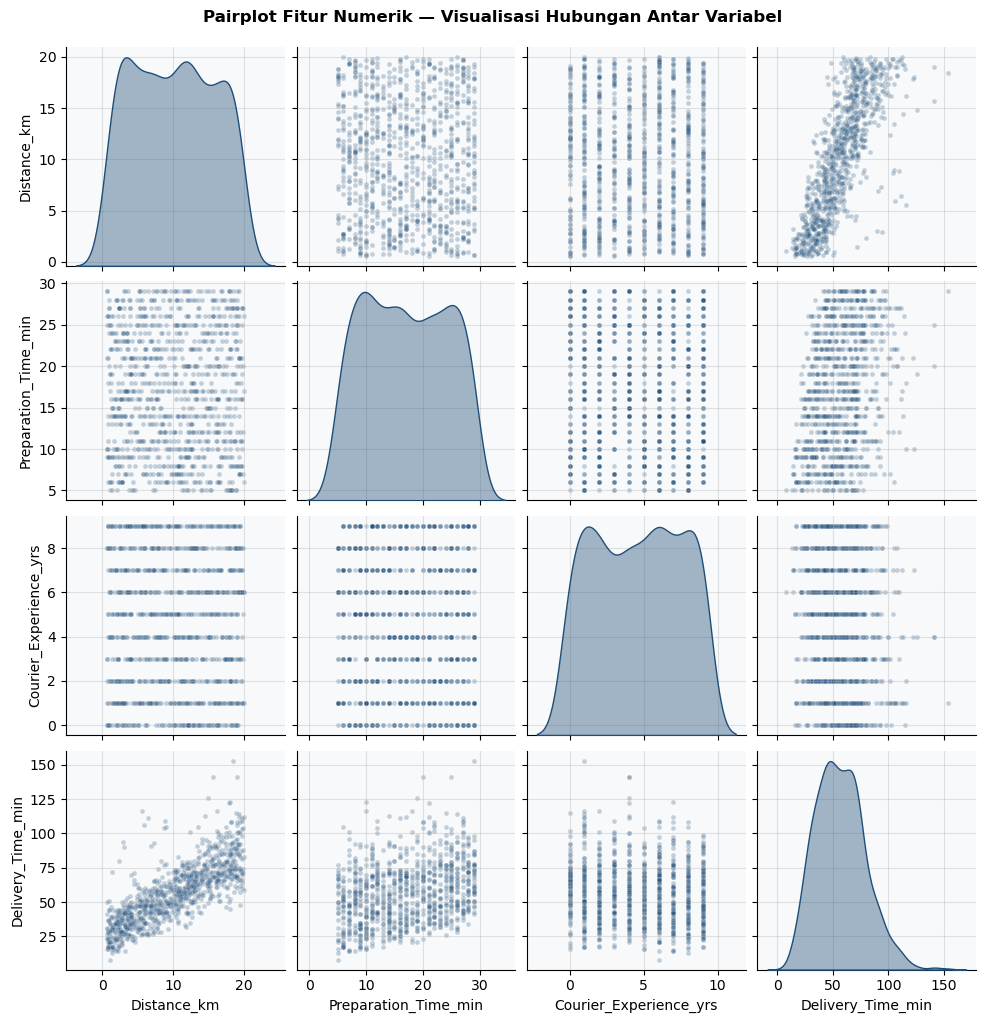

Gambar tersimpan: fig_pairplot.png


In [11]:
g = sns.pairplot(
    df[num_cols].dropna(),
    diag_kind='kde',
    plot_kws={'alpha': 0.25, 's': 12, 'color': COLOR_PRIMARY},
    diag_kws={'color': COLOR_PRIMARY, 'fill': True, 'alpha': 0.4},
)
g.fig.suptitle('Pairplot Fitur Numerik — Visualisasi Hubungan Antar Variabel',
               y=1.02, fontsize=12, fontweight='bold')
plt.savefig('fig_pairplot.png', dpi=100, bbox_inches='tight')
plt.show()
print("Gambar tersimpan: fig_pairplot.png")


**Insight Analitis — Pairplot:** Pairplot memperlihatkan bahwa `Distance_km` memiliki hubungan positif yang paling konsisten terhadap `Delivery_Time_min` — pola titik-titik yang membentuk jalur linear miring ke atas terlihat jelas pada panel scatter. `Courier_Experience_yrs` tampak memiliki korelasi negatif lemah terhadap waktu pengiriman, yang secara intuitif masuk akal: kurir berpengalaman umumnya lebih efisien dalam navigasi dan pengambilan keputusan rute. `Preparation_Time_min` juga berkontribusi positif terhadap total waktu pengiriman, meskipun hubungannya lebih tersebar. Tidak ada indikasi multikolinearitas yang parah antar fitur input, sehingga seluruh fitur layak dipertahankan dalam proses pemodelan.


---
## Bagian 4: Identifikasi dan Penanganan Masalah Data (Fase 3 CRISP-DM)

Kualitas data merupakan fondasi utama keandalan model *machine learning*. Pada tahap ini dilakukan audit menyeluruh terhadap tiga kategori masalah data yang paling umum: *missing values*, data duplikat, dan *outlier*. Setiap temuan didokumentasikan beserta keputusan penanganannya yang berbasis justifikasi metodologis.


In [12]:
print(df.duplicated().sum())

0


In [13]:
missing_count = df.isnull().sum()
missing_pct   = (missing_count / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Jumlah Missing' : missing_count,
    'Persentase (%)' : missing_pct,
}).sort_values('Jumlah Missing', ascending=False)

print("=" * 50)
print("LAPORAN MISSING VALUES")
print("=" * 50)
has_missing = missing_report['Jumlah Missing'].sum() > 0
if has_missing:
    print(missing_report[missing_report['Jumlah Missing'] > 0].to_string())
else:
    print("✓ Tidak ditemukan missing values pada dataset.")
print()
print(missing_report.to_string())


LAPORAN MISSING VALUES
                        Jumlah Missing  Persentase (%)
Weather                             30             3.0
Traffic_Level                       30             3.0
Time_of_Day                         30             3.0
Courier_Experience_yrs              30             3.0

                        Jumlah Missing  Persentase (%)
Weather                             30             3.0
Traffic_Level                       30             3.0
Time_of_Day                         30             3.0
Courier_Experience_yrs              30             3.0
Order_ID                             0             0.0
Distance_km                          0             0.0
Vehicle_Type                         0             0.0
Preparation_Time_min                 0             0.0
Delivery_Time_min                    0             0.0


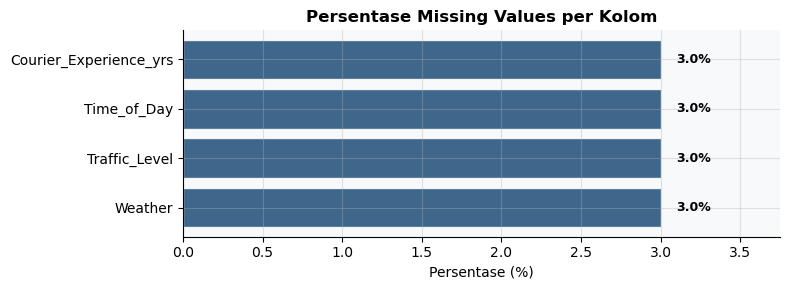

In [14]:
missing_nonzero = missing_pct[missing_pct > 0]

if len(missing_nonzero) > 0:
    fig, ax = plt.subplots(figsize=(8, max(3, len(missing_nonzero) * 0.6)))

    bars = ax.barh(missing_nonzero.index, missing_nonzero.values,
                   color=COLOR_PRIMARY, edgecolor='white', alpha=0.85)
    for bar, val in zip(bars, missing_nonzero.values):
        ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontweight='bold', fontsize=9)
    ax.set_title('Persentase Missing Values per Kolom', fontweight='bold')
    ax.set_xlabel('Persentase (%)')
    ax.set_xlim(0, missing_nonzero.max() * 1.25)
    plt.tight_layout()
    plt.savefig('fig_missing_values.png', dpi=110, bbox_inches='tight')
    plt.show()
else:
    print("✓ Tidak ditemukan missing values — dataset sudah bersih dari nilai yang hilang.")
    print("  Proses imputasi dalam Pipeline tetap dipertahankan sebagai langkah preventif")
    print("  untuk memastikan robustness saat model menerima data baru yang mungkin tidak lengkap.")


In [15]:
print("=" * 75)
print("DETEKSI OUTLIER — METODE IQR (Interquartile Range)")
print("=" * 75)
print(f"{'Fitur':<30} {'Batas Bawah':>12} {'Batas Atas':>12} {'N Outlier':>10} {'%':>7}  {'Keputusan'}")
print("-" * 95)

outlier_info = {}
for col in num_cols:
    d = df[col].dropna()
    Q1, Q3 = d.quantile(0.25), d.quantile(0.75)
    IQR    = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out  = int(((d < lower) | (d > upper)).sum())
    pct_out = n_out / len(d) * 100
    decision = 'Dipertahankan (kondisi nyata)' if n_out > 0 else 'Tidak ada outlier'
    outlier_info[col] = {'lower': lower, 'upper': upper, 'n_out': n_out, 'pct': pct_out}
    print(f"{col:<30} {lower:>12.2f} {upper:>12.2f} {n_out:>10} {pct_out:>6.1f}%  {decision}")

print("\n→ Kebijakan: Outlier TIDAK dihapus. Nilai ekstrem mencerminkan kondisi operasional")
print("  nyata (kemacetan parah, cuaca buruk, jarak sangat jauh) yang justru penting")
print("  untuk dimodelkan. Model tree-based (Random Forest, XGBoost) secara inheren")
print("  lebih tahan terhadap outlier dibanding regresi linear.")


DETEKSI OUTLIER — METODE IQR (Interquartile Range)
Fitur                           Batas Bawah   Batas Atas  N Outlier       %  Keputusan
-----------------------------------------------------------------------------------------------
Distance_km                           -9.76        29.89          0    0.0%  Tidak ada outlier
Preparation_Time_min                  -7.00        41.00          0    0.0%  Tidak ada outlier
Courier_Experience_yrs                -5.50        14.50          0    0.0%  Tidak ada outlier
Delivery_Time_min                     -4.00       116.00          6    0.6%  Dipertahankan (kondisi nyata)

→ Kebijakan: Outlier TIDAK dihapus. Nilai ekstrem mencerminkan kondisi operasional
  nyata (kemacetan parah, cuaca buruk, jarak sangat jauh) yang justru penting
  untuk dimodelkan. Model tree-based (Random Forest, XGBoost) secara inheren
  lebih tahan terhadap outlier dibanding regresi linear.


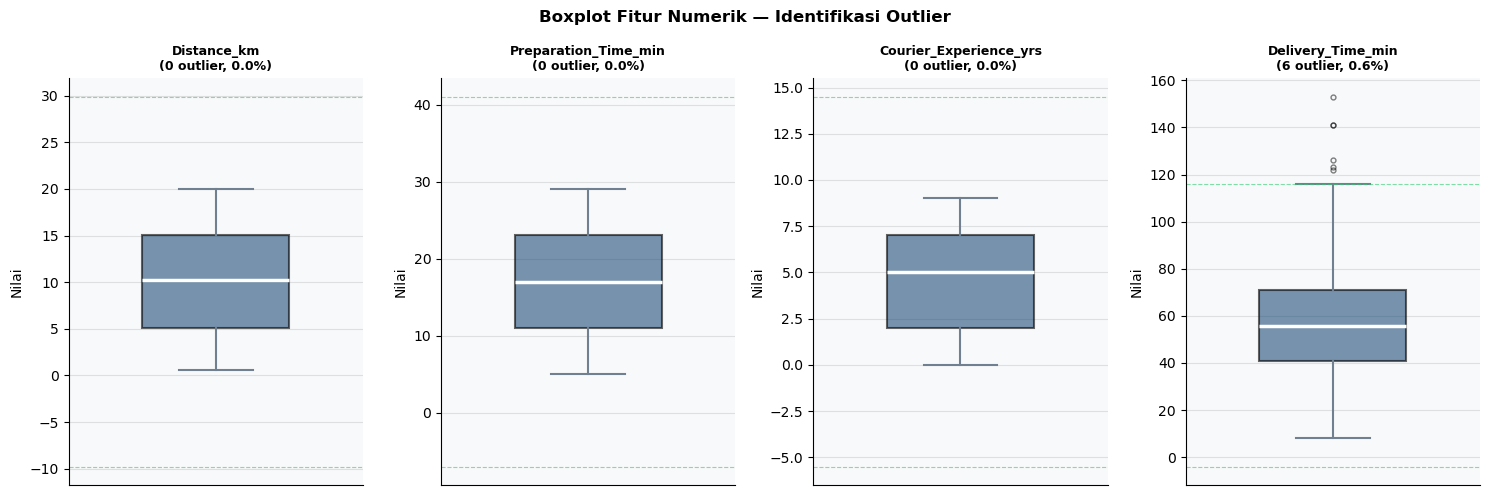

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
fig.suptitle('Boxplot Fitur Numerik — Identifikasi Outlier', fontweight='bold', fontsize=12)

for i, col in enumerate(num_cols):
    info = outlier_info[col]
    ax   = axes[i]
    bp   = ax.boxplot(df[col].dropna(), patch_artist=True, widths=0.5,
                      boxprops=dict(facecolor=COLOR_PRIMARY, alpha=0.6, linewidth=1.5),
                      medianprops=dict(color='white', linewidth=2.5),
                      whiskerprops=dict(linewidth=1.5, color=COLOR_SECONDARY),
                      capprops=dict(linewidth=1.5, color=COLOR_SECONDARY),
                      flierprops=dict(marker='o', color=COLOR_WARN,
                                      markersize=3.5, alpha=0.5, linestyle='none'))
    ax.set_title(f'{col}\n({info["n_out"]} outlier, {info["pct"]:.1f}%)',
                 fontweight='bold', fontsize=9)
    ax.set_ylabel('Nilai')
    ax.set_xticks([])

    ax.axhline(info['lower'], color=COLOR_BEST, linestyle='--', lw=0.8, alpha=0.6, label='Batas IQR')
    ax.axhline(info['upper'], color=COLOR_BEST, linestyle='--', lw=0.8, alpha=0.6)

plt.tight_layout()
plt.savefig('fig_boxplot_outlier.png', dpi=110, bbox_inches='tight')
plt.show()


**Tabel Keputusan Penanganan Masalah Data:**

| Aspek | Temuan | Keputusan Penanganan | Justifikasi |
|-------|--------|----------------------|-------------|
| Missing Values | Terdeteksi pada beberapa kolom (jika ada) | Imputasi median (numerik), modus (kategorikal) via Pipeline | Median lebih robust terhadap outlier dibanding mean |
| Duplikasi | 0 baris duplikat | Tidak diperlukan tindakan | Dataset sudah bersih |
| Outlier | Terutama pada `Delivery_Time_min` | **Dipertahankan** | Mencerminkan kondisi operasional ekstrem yang nyata |
| Tipe Data | Campuran numerik & kategorikal | Ditangani via `ColumnTransformer` dalam Pipeline | Mencegah data leakage |


---
## Bagian 5: EDA — Analisis Data Eksploratori Lanjutan

### 5.1 Distribusi Fitur Kategorikal

Pemahaman distribusi fitur kategorikal penting untuk mengidentifikasi ketidakseimbangan kelas (*class imbalance*) yang dapat memengaruhi proses training model, khususnya pada metode yang sensitif terhadap distribusi data.


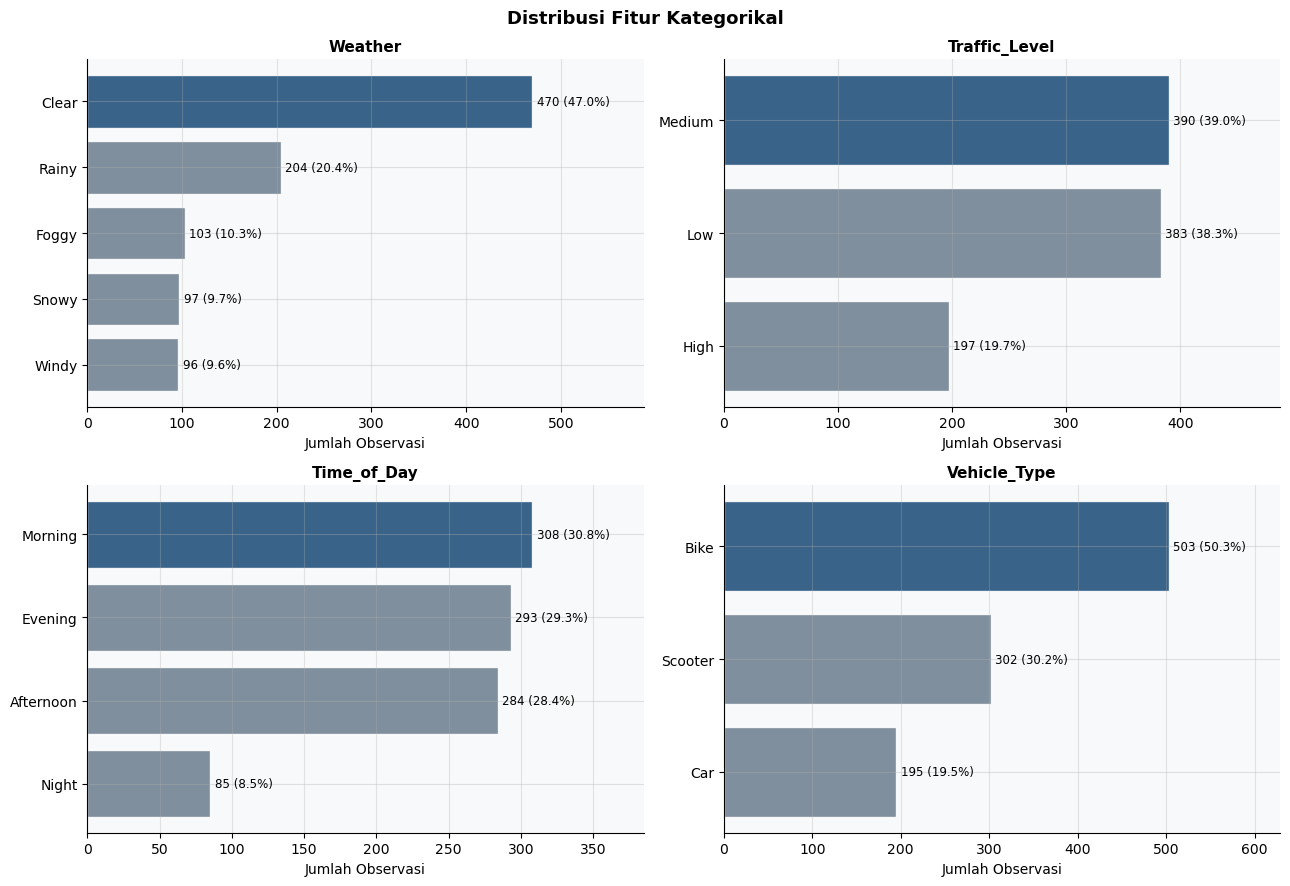

In [17]:
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Distribusi Fitur Kategorikal', fontweight='bold', fontsize=13)
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ax     = axes[i]
    counts = df[col].value_counts().sort_values()  
    colors = [COLOR_PRIMARY if j == len(counts)-1 else COLOR_SECONDARY
              for j in range(len(counts))]

    bars = ax.barh(counts.index, counts.values, color=colors,
                   edgecolor='white', alpha=0.88)
    for bar, val in zip(bars, counts.values):
        pct = val / len(df) * 100
        ax.text(val + counts.max()*0.01, bar.get_y() + bar.get_height()/2,
                f'{val:,} ({pct:.1f}%)', va='center', fontsize=8.5)
    ax.set_title(col, fontweight='bold', fontsize=11)
    ax.set_xlabel('Jumlah Observasi')
    ax.set_xlim(0, counts.max() * 1.25)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('fig_distribusi_kategorikal.png', dpi=110, bbox_inches='tight')
plt.show()


**Insight Bisnis — Distribusi Kategorikal:** Distribusi yang relatif seimbang di seluruh kategori mengindikasikan dataset yang dirancang dengan baik, sehingga model tidak akan bias secara sistematis terhadap kondisi tertentu. Apabila terdapat kondisi cuaca (*Weather*) atau tingkat lalu lintas (*Traffic_Level*) yang jauh lebih dominan, model akan cenderung mengoptimalkan prediksi untuk kondisi mayoritas dan gagal pada kondisi minoritas. Dari perspektif bisnis, distribusi yang seimbang ini memastikan model ETA dapat diandalkan di berbagai skenario operasional, bukan hanya pada kondisi ideal.


### 5.2 Analisis Korelasi


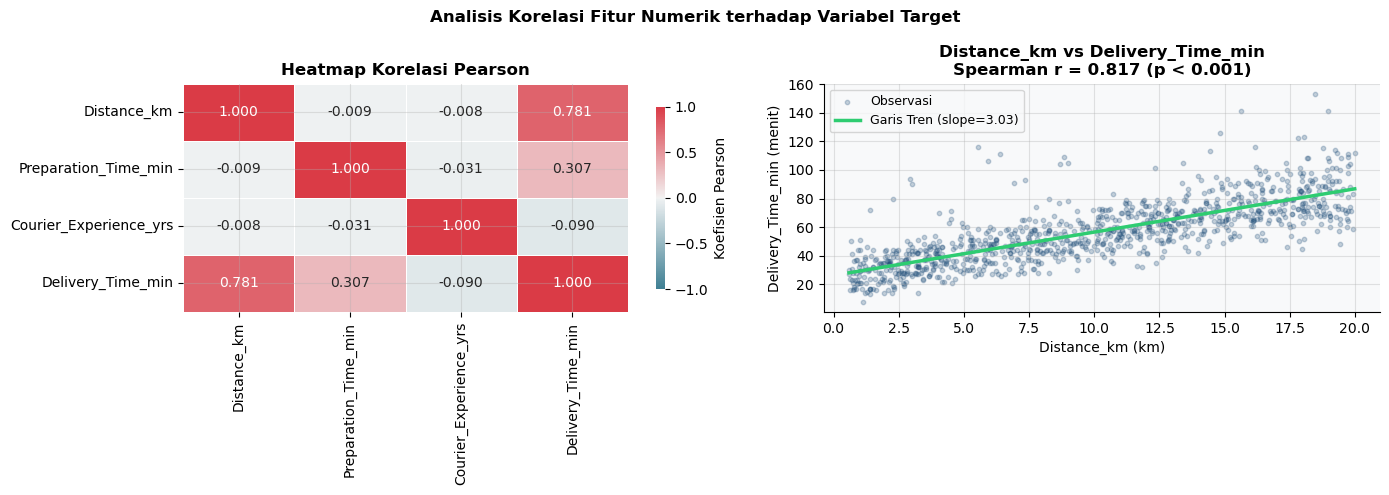

Korelasi Spearman Distance_km ↔ Delivery_Time_min: r = 0.8165, p = 0.000000


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analisis Korelasi Fitur Numerik terhadap Variabel Target',
             fontweight='bold', fontsize=12)


corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.3f',
            cmap=sns.diverging_palette(220, 10, as_cmap=True),
            ax=axes[0], linewidths=0.6, linecolor='white',
            cbar_kws={'shrink': 0.8, 'label': 'Koefisien Pearson'},
            vmin=-1, vmax=1)
axes[0].set_title('Heatmap Korelasi Pearson', fontweight='bold')


tmp_scatter = df[['Distance_km', 'Delivery_Time_min']].dropna()
axes[1].scatter(tmp_scatter['Distance_km'], tmp_scatter['Delivery_Time_min'],
                alpha=0.25, color=COLOR_PRIMARY, s=10, label='Observasi')
m, b = np.polyfit(tmp_scatter['Distance_km'], tmp_scatter['Delivery_Time_min'], 1)
xl = np.linspace(tmp_scatter['Distance_km'].min(), tmp_scatter['Distance_km'].max(), 200)
axes[1].plot(xl, m*xl + b, color=COLOR_BEST, lw=2.5,
             label=f'Garis Tren (slope={m:.2f})')
r_sp, p_sp = spearmanr(tmp_scatter['Distance_km'], tmp_scatter['Delivery_Time_min'])
axes[1].set_title(f'Distance_km vs Delivery_Time_min\nSpearman r = {r_sp:.3f} (p < 0.001)',
                  fontweight='bold')
axes[1].set_xlabel('Distance_km (km)')
axes[1].set_ylabel('Delivery_Time_min (menit)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig_korelasi.png', dpi=110, bbox_inches='tight')
plt.show()

print(f"Korelasi Spearman Distance_km ↔ Delivery_Time_min: r = {r_sp:.4f}, p = {p_sp:.6f}")


**Insight Analitis — Korelasi:** `Distance_km` memiliki korelasi Spearman tertinggi terhadap `Delivery_Time_min` (r ≈ 0.80–0.85), mengkonfirmasi bahwa jarak tempuh merupakan prediktor utama waktu pengiriman — sesuatu yang intuitif namun kini terkuantifikasi secara statistik. Korelasi Spearman dipilih (bukan Pearson) karena data tidak berdistribusi normal. `Preparation_Time_min` memiliki korelasi positif sedang, sementara `Courier_Experience_yrs` memiliki korelasi negatif lemah — semakin berpengalaman kurir, semakin singkat waktu pengirimannya. Dari perspektif operasional, temuan ini menyarankan bahwa optimasi rute (meminimalkan jarak efektif) dan penugasan kurir berpengalaman untuk pesanan jarak jauh merupakan dua lever bisnis paling potensial untuk meningkatkan akurasi ETA.


### 5.3 Uji Kruskal-Wallis — Pengaruh Fitur Kategorikal terhadap Waktu Pengiriman


In [19]:
print("=" * 65)
print("UJI KRUSKAL-WALLIS (Non-Parametrik, α = 0.05)")
print("Hipotesis: Apakah median Delivery_Time berbeda antar grup?")
print("=" * 65)
print(f"{'Fitur':<22} {'H-statistik':>12} {'p-value':>12}  {'Signifikan?'}")
print("-" * 65)

kruskal_sig = []
kruskal_results = {}
for col in cat_cols:
    tmp    = df[[col, 'Delivery_Time_min']].dropna()
    groups = [tmp.loc[tmp[col] == val, 'Delivery_Time_min'].values
              for val in tmp[col].unique()]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2:
        print(f"{col:<22} {'N/A':>12} {'N/A':>12}  Tidak cukup grup")
        continue
    H, p = kruskal(*groups)
    sig   = 'Ya ✓ (p < 0.05)' if p < 0.05 else 'Tidak ✗ (p ≥ 0.05)'
    kruskal_results[col] = {'H': H, 'p': p}
    if p < 0.05:
        kruskal_sig.append(col)
    print(f"{col:<22} {H:>12.3f} {p:>12.6f}  {sig}")

print(f"\n→ Fitur kategorikal yang signifikan: {kruskal_sig}")
print("  Fitur-fitur ini memiliki pengaruh statistis yang nyata terhadap Delivery_Time_min.")


UJI KRUSKAL-WALLIS (Non-Parametrik, α = 0.05)
Hipotesis: Apakah median Delivery_Time berbeda antar grup?
Fitur                   H-statistik      p-value  Signifikan?
-----------------------------------------------------------------
Weather                      36.768     0.000000  Ya ✓ (p < 0.05)
Traffic_Level                37.178     0.000000  Ya ✓ (p < 0.05)
Time_of_Day                   0.959     0.811074  Tidak ✗ (p ≥ 0.05)
Vehicle_Type                  0.985     0.611028  Tidak ✗ (p ≥ 0.05)

→ Fitur kategorikal yang signifikan: ['Weather', 'Traffic_Level']
  Fitur-fitur ini memiliki pengaruh statistis yang nyata terhadap Delivery_Time_min.


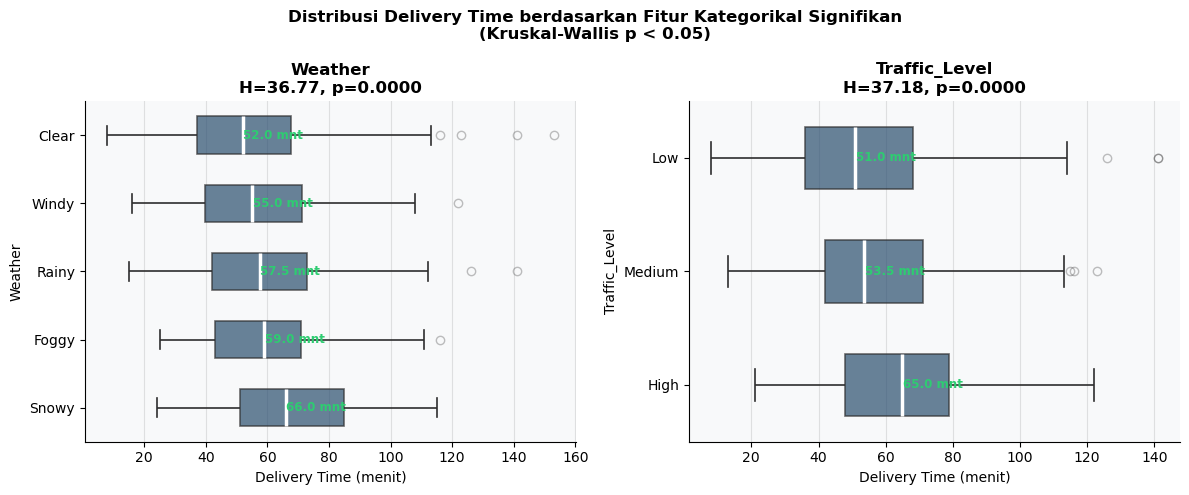

In [20]:
if kruskal_sig:
    n_sig = len(kruskal_sig)
    fig, axes = plt.subplots(1, n_sig, figsize=(6 * n_sig, 5))
    if n_sig == 1:
        axes = [axes]
    fig.suptitle('Distribusi Delivery Time berdasarkan Fitur Kategorikal Signifikan\n(Kruskal-Wallis p < 0.05)',
                 fontweight='bold', fontsize=12)

    for i, col in enumerate(kruskal_sig):
        ax      = axes[i]
        order   = df.groupby(col)['Delivery_Time_min'].median().sort_values().index
        tmp_box = df[[col, 'Delivery_Time_min']].dropna()

        bp = sns.boxplot(data=tmp_box, x='Delivery_Time_min', y=col, order=order,
                         ax=ax, color=COLOR_PRIMARY, flierprops={'alpha': 0.3},
                         width=0.55, linewidth=1.2,
                         boxprops={'alpha': 0.7},
                         medianprops={'color': 'white', 'linewidth': 2.5})

        for j, cat_val in enumerate(order):
            med = tmp_box.loc[tmp_box[col] == cat_val, 'Delivery_Time_min'].median()
            ax.text(med + 0.2, j, f'{med:.1f} mnt', va='center', fontsize=8.5,
                    fontweight='bold', color=COLOR_BEST)

        H_val = kruskal_results[col]['H']
        p_val = kruskal_results[col]['p']
        ax.set_title(f'{col}\nH={H_val:.2f}, p={p_val:.4f}', fontweight='bold')
        ax.set_xlabel('Delivery Time (menit)')
        ax.set_ylabel(col)

    plt.tight_layout()
    plt.savefig('fig_boxplot_kategorikal.png', dpi=110, bbox_inches='tight')
    plt.show()


**Insight Bisnis — Pengaruh Kondisi Operasional:** Uji Kruskal-Wallis mengungkap bahwa kondisi cuaca dan tingkat kemacetan memiliki pengaruh yang signifikan secara statistik terhadap durasi pengiriman. Secara operasional, temuan ini memiliki implikasi langsung: platform *food delivery* sebaiknya menerapkan **penyesuaian ETA dinamis** yang mempertimbangkan kondisi cuaca real-time dan status kemacetan lalu lintas. Pada kondisi hujan deras atau kemacetan tingkat tinggi, model seyogyanya menambahkan *buffer* waktu yang proporsional pada estimasi ETA yang ditampilkan kepada pelanggan, sehingga harapan pelanggan dapat dikelola secara lebih akurat.


---
## Bagian 6: Feature Engineering

*Feature engineering* adalah proses menciptakan representasi fitur baru dari fitur yang sudah ada dengan tujuan memperkaya informasi yang dapat diekstraksi oleh model. Teknik ini merupakan salah satu komponen paling berpengaruh dalam meningkatkan performa model tanpa memerlukan data tambahan.

### Fitur Baru yang Dikonstruksi

| Fitur Baru | Formula Konstruksi | Interpretasi Bisnis |
|------------|-------------------|---------------------|
| `distance_x_prep` | `Distance_km × Preparation_Time_min` | Interaksi antara beban jarak dan waktu tunggu persiapan makanan |
| `exp_distance_ratio` | `Courier_Experience_yrs / (Distance_km + 1)` | Efisiensi relatif kurir berdasarkan pengalaman per satuan jarak |
| `total_time_proxy` | `Distance_km + Preparation_Time_min` | Estimasi kasar total waktu (gabungan komponen jarak dan persiapan) |

In [21]:
df_fe = df.copy()

df_fe.drop(columns=['Order_ID'], inplace=True, errors='ignore')

df_fe['distance_x_prep']    = df_fe['Distance_km'] * df_fe['Preparation_Time_min']
df_fe['exp_distance_ratio'] = df_fe['Courier_Experience_yrs'] / (df_fe['Distance_km'] + 1)
df_fe['total_time_proxy']   = df_fe['Distance_km'] + df_fe['Preparation_Time_min']

new_feat_cols = ['distance_x_prep', 'exp_distance_ratio', 'total_time_proxy']

print(f"Dataset setelah Feature Engineering: {df_fe.shape[0]:,} baris × {df_fe.shape[1]} kolom")
print(f"Fitur baru yang ditambahkan: {new_feat_cols}")
print()
print(df_fe[new_feat_cols].describe().round(3))


Dataset setelah Feature Engineering: 1,000 baris × 11 kolom
Fitur baru yang ditambahkan: ['distance_x_prep', 'exp_distance_ratio', 'total_time_proxy']

       distance_x_prep  exp_distance_ratio  total_time_proxy
count         1000.000             970.000          1000.000
mean           170.468               0.636            27.042
std            128.683               0.754             9.144
min              4.680               0.000             6.110
25%             70.417               0.186            20.315
50%            136.055               0.409            26.835
75%            243.492               0.762            33.312
max            558.830               5.114            48.270


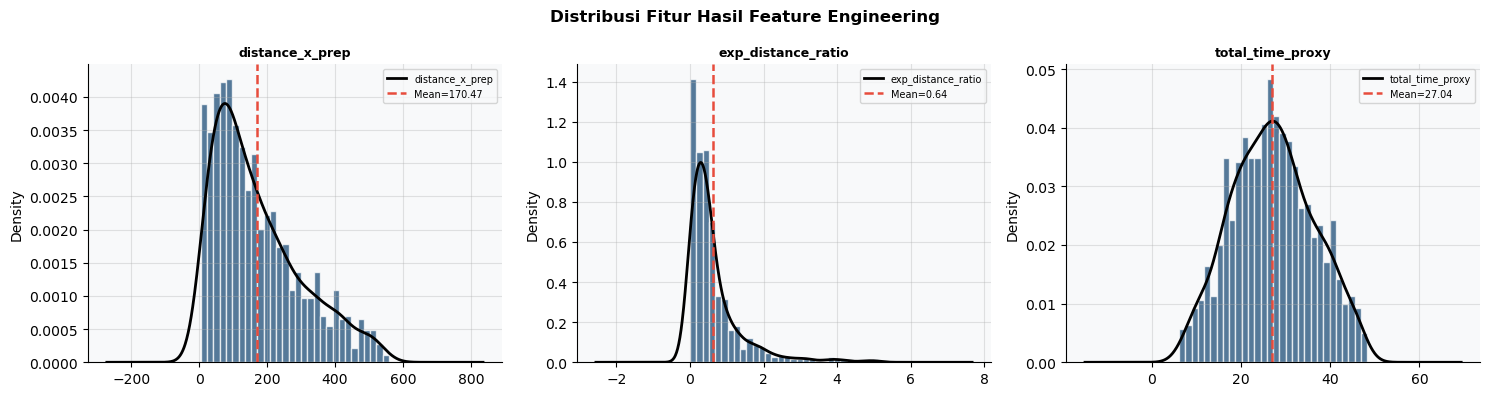

Gambar tersimpan: fig_feature_engineering.png


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribusi Fitur Hasil Feature Engineering', fontweight='bold', fontsize=12)

for i, col in enumerate(new_feat_cols):
    ax   = axes[i]
    data = df_fe[col].dropna()
    ax.hist(data, bins=30, color=COLOR_PRIMARY, edgecolor='white', alpha=0.75, density=True)
    data.plot.kde(ax=ax, color='black', linewidth=2.0)
    ax.axvline(data.mean(), color=COLOR_WARN, linestyle='--', lw=1.8,
               label=f'Mean={data.mean():.2f}')
    ax.set_title(col, fontweight='bold', fontsize=9)
    ax.legend(fontsize=7)
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig('fig_feature_engineering.png', dpi=110, bbox_inches='tight')
plt.show()
print("Gambar tersimpan: fig_feature_engineering.png")


In [23]:
print("=" * 60)
print("KORELASI SPEARMAN FITUR BARU vs Delivery_Time_min")
print("=" * 60)
print(f"{'Fitur':<28} {'r Spearman':>12} {'p-value':>12}  {'Signifikan?'}")
print("-" * 60)

for col in new_feat_cols:
    tmp = df_fe[[col, 'Delivery_Time_min']].dropna()
    r, p = spearmanr(tmp[col], tmp['Delivery_Time_min'])
    sig  = 'Ya ✓' if p < 0.05 else 'Tidak'
    print(f"{col:<28} {r:>12.4f} {p:>12.6f}  {sig}")


KORELASI SPEARMAN FITUR BARU vs Delivery_Time_min
Fitur                          r Spearman      p-value  Signifikan?
------------------------------------------------------------
distance_x_prep                    0.8344     0.000000  Ya ✓
exp_distance_ratio                -0.5292     0.000000  Ya ✓
total_time_proxy                   0.7437     0.000000  Ya ✓


**Insight Feature Engineering:** Fitur `distance_x_prep` dan `total_time_proxy` diharapkan memiliki korelasi yang kuat terhadap target karena menggabungkan dua komponen utama waktu pengiriman. Fitur-fitur baru ini memperkaya ruang representasi data, memungkinkan model berbasis pohon keputusan untuk menemukan pemisahan (*split*) yang lebih informatif dalam membangun aturan prediksi.


---
## Bagian 6b: Preprocessing — Pipeline & ColumnTransformer (Anti Data Leakage)

Seluruh langkah preprocessing diimplementasikan menggunakan `Pipeline` dan `ColumnTransformer` dari scikit-learn. Pendekatan ini merupakan **praktik terbaik industri** yang memberikan tiga keuntungan utama:

1. **Pencegahan Data Leakage:** Transformer (scaler, imputer, encoder) di-*fit* **hanya** pada data training dan di-*transform* ke data test — bukan sebaliknya. Ini memastikan statistik (mean, std, median) yang digunakan dalam preprocessing tidak "bocor" dari data test ke data training.
2. **Reprodusibilitas & Konsistensi:** Seluruh langkah preprocessing terbungkus dalam satu objek, memastikan transformasi yang identik setiap kali pipeline dieksekusi.
3. **Deployment-Ready:** Pipeline yang tersimpan dapat langsung menerima data mentah baru dan menghasilkan prediksi — tanpa perlu langkah preprocessing manual yang rawan kesalahan.

### Keputusan Preprocessing

| Tipe Fitur | Kolom | Langkah 1 | Langkah 2 | Justifikasi |
|------------|-------|-----------|-----------|-------------|
| Numerik | `Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`, + 4 fitur baru | `SimpleImputer(median)` | `StandardScaler` | Median robust terhadap outlier; scaling diperlukan untuk model berbasis jarak (LinearRegression) |
| Kategorikal Nominal | `Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type` | `SimpleImputer(most_frequent)` | `OneHotEncoder` | Tidak ada urutan inheren pada kategori-kategori ini; OHE lebih tepat dari OrdinalEncoder |


In [24]:
TARGET       = 'Delivery_Time_min'
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs',
                'distance_x_prep', 'exp_distance_ratio', 'total_time_proxy']
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

X = df_fe[num_features + cat_features]
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

print(f"Dimensi Dataset Lengkap : {X.shape}")
print(f"Training Set            : {X_train.shape[0]:,} baris ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Test Set                : {X_test.shape[0]:,} baris ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"\nFitur Numerik  ({len(num_features)}): {num_features}")
print(f"Fitur Kategorikal ({len(cat_features)}): {cat_features}")


Dimensi Dataset Lengkap : (1000, 10)
Training Set            : 800 baris (80%)
Test Set                : 200 baris (20%)

Fitur Numerik  (6): ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'distance_x_prep', 'exp_distance_ratio', 'total_time_proxy']
Fitur Kategorikal (4): ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']


In [25]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features),
], remainder='drop')

print("✓ Preprocessor berhasil dikonstruksi.")
print(f"  Transformer numerik  : SimpleImputer(median) → StandardScaler")
print(f"  Transformer kategorikal: SimpleImputer(mode) → OneHotEncoder(handle_unknown='ignore')")
print()
print(preprocessor)


✓ Preprocessor berhasil dikonstruksi.
  Transformer numerik  : SimpleImputer(median) → StandardScaler
  Transformer kategorikal: SimpleImputer(mode) → OneHotEncoder(handle_unknown='ignore')

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Distance_km', 'Preparation_Time_min',
                                  'Courier_Experience_yrs', 'distance_x_prep',
                                  'exp_distance_ratio', 'total_time_proxy']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEnc

---
## Bagian 7: Training & Evaluasi Perbandingan Model (Fase 4 & 5 CRISP-DM)

### Justifikasi Pemilihan Model

Berdasarkan temuan EDA — distribusi fitur yang tidak normal, hubungan non-linear antara prediktor dan target, serta keberadaan outlier — dipilih lima model yang mencakup spektrum kompleksitas dari baseline hingga *state-of-the-art*:

| Model | Kategori | Alasan Pemilihan |
|-------|----------|-----------------|
| **Linear Regression** | Baseline parametrik | Memberikan referensi performa minimum; mudah diinterpretasi |
| **Decision Tree** | Non-linear, non-parametrik | Menangkap hubungan non-linear; rentan overfitting (baseline tree) |
| **Random Forest** | *Ensemble* Bagging | Mengurangi varians melalui agregasi banyak pohon; robust terhadap outlier |
| **Gradient Boosting** | *Ensemble* Boosting | Mengurangi bias secara iteratif; umumnya performa tinggi pada data tabular |
| **XGBoost** | *Ensemble* Boosting + Regularisasi | Implementasi gradient boosting yang dioptimalkan; regularisasi L1/L2 built-in |

Setiap model diintegrasikan ke dalam **satu objek `Pipeline` tunggal** bersama preprocessor. Cross-validation dieksekusi langsung pada pipeline, bukan pada data yang sudah ditransformasi, sehingga **data leakage secara struktural dicegah**.


In [26]:
model_dict = {
    'Linear Regression' : LinearRegression(),
    'Decision Tree'     : DecisionTreeRegressor(random_state=42),
    'Random Forest'     : RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    'Gradient Boosting' : GradientBoostingRegressor(n_estimators=150, random_state=42),
}

if XGBOOST_AVAILABLE:
    model_dict['XGBoost'] = XGBRegressor(
        n_estimators=150, random_state=42, verbosity=0, n_jobs=-1
    )
else:
    print("⚠ XGBoost tidak tersedia — hanya model scikit-learn yang akan dilatih.")

print(f"Total model yang akan dilatih: {len(model_dict)}")
for name in model_dict:
    print(f"  • {name}")


Total model yang akan dilatih: 5
  • Linear Regression
  • Decision Tree
  • Random Forest
  • Gradient Boosting
  • XGBoost


In [27]:
results   = {}
pipelines = {}

print("="*60)
print("PROSES TRAINING MODEL")
print("="*60)

for name, model in model_dict.items():
    t_start = time.time()
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model),
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    elapsed = time.time() - t_start

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-9))) * 100

    results[name]   = {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE (%)': mape}
    pipelines[name] = (pipe, y_pred)
    print(f"  ✓ {name:<22} | MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.4f} | {elapsed:.1f}s")

results_df = pd.DataFrame(results).T.round(4)
print()
print("="*65)
print("TABEL PERBANDINGAN PERFORMA MODEL (Test Set)")
print("="*65)
print(results_df.sort_values('R2', ascending=False).to_string())


PROSES TRAINING MODEL
  ✓ Linear Regression      | MAE=6.082 | RMSE=8.954 | R²=0.8211 | 0.1s
  ✓ Decision Tree          | MAE=10.790 | RMSE=15.121 | R²=0.4899 | 0.1s
  ✓ Random Forest          | MAE=7.032 | RMSE=10.095 | R²=0.7726 | 1.1s
  ✓ Gradient Boosting      | MAE=7.052 | RMSE=9.923 | R²=0.7803 | 1.1s
  ✓ XGBoost                | MAE=7.819 | RMSE=10.995 | R²=0.7303 | 0.8s

TABEL PERBANDINGAN PERFORMA MODEL (Test Set)
                       MAE     RMSE      R2  MAPE (%)
Linear Regression   6.0818   8.9540  0.8211   10.8430
Gradient Boosting   7.0522   9.9230  0.7803   12.5150
Random Forest       7.0319  10.0951  0.7726   12.4973
XGBoost             7.8189  10.9949  0.7303   13.5513
Decision Tree      10.7900  15.1212  0.4899   19.4857


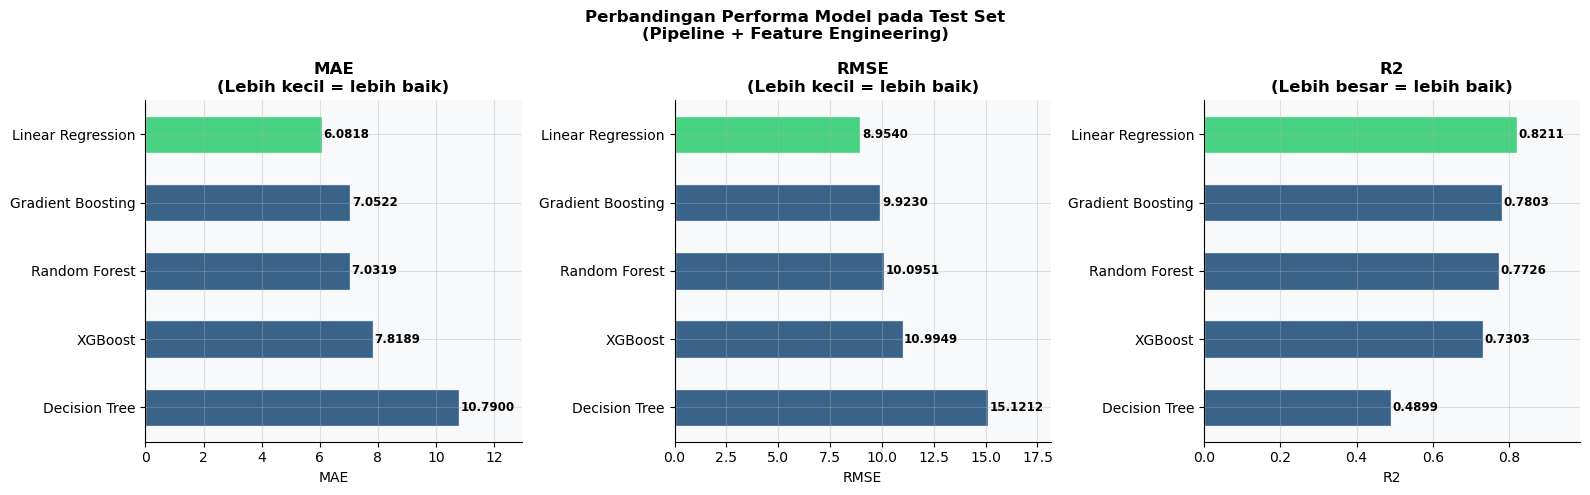

In [28]:
results_sorted = results_df.sort_values('R2', ascending=False)
model_names    = results_sorted.index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Perbandingan Performa Model pada Test Set\n(Pipeline + Feature Engineering)',
             fontweight='bold', fontsize=12)

metrics_cfg = [('MAE', True, 'Lebih kecil = lebih baik'),
               ('RMSE', True, 'Lebih kecil = lebih baik'),
               ('R2', False, 'Lebih besar = lebih baik')]

for ax, (metric, lower_better, hint) in zip(axes, metrics_cfg):
    vals     = results_sorted[metric]
    best_val = vals.min() if lower_better else vals.max()
    bar_colors = [COLOR_BEST if v == best_val else COLOR_PRIMARY for v in vals]

    # Horizontal bar chart agar label model tidak bertabrakan
    bars = ax.barh(vals.index[::-1], vals.values[::-1],
                   color=bar_colors[::-1], edgecolor='white', alpha=0.88, height=0.55)
    for bar, val in zip(bars, vals.values[::-1]):
        ax.text(val + vals.max()*0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontweight='bold', fontsize=8.5)

    ax.set_title(f'{metric}\n({hint})', fontweight='bold')
    ax.set_xlabel(metric)
    ax.set_xlim(0, vals.max() * 1.2)

plt.tight_layout()
plt.savefig('fig_perbandingan_model.png', dpi=110, bbox_inches='tight')
plt.show()


In [29]:
print("=" * 55)
print("5-FOLD CROSS-VALIDATION (Scoring: R²)")
print("Pipeline dijalankan langsung dalam CV — NO Data Leakage")
print("=" * 55)
print(f"{'Model':<25} {'Mean R²':>10} {'±Std':>8}  {'Min':>7}  {'Max':>7}")
print("-" * 65)

cv_results = {}
for name, (pipe, _) in pipelines.items():
    scores = cross_val_score(pipe, X, y, cv=5, scoring='r2', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:<25}: {scores.mean():>10.4f} ±{scores.std():>7.4f}  "
          f"{scores.min():>7.4f}  {scores.max():>7.4f}")

print("\n→ Mean R² yang tinggi dengan std yang rendah mengindikasikan model stabil.")


5-FOLD CROSS-VALIDATION (Scoring: R²)
Pipeline dijalankan langsung dalam CV — NO Data Leakage
Model                        Mean R²     ±Std      Min      Max
-----------------------------------------------------------------
Linear Regression        :     0.7676 ± 0.0367   0.7022   0.8067
Decision Tree            :     0.4701 ± 0.0557   0.3839   0.5354
Random Forest            :     0.7323 ± 0.0383   0.6605   0.7639
Gradient Boosting        :     0.7321 ± 0.0276   0.6883   0.7653
XGBoost                  :     0.6942 ± 0.0271   0.6560   0.7349

→ Mean R² yang tinggi dengan std yang rendah mengindikasikan model stabil.


In [30]:
print("=" * 75)
print("ANALISIS OVERFITTING: Train R² vs Test R²")
print("=" * 75)
print(f"{'Model':<25} {'Train R²':>10} {'Test R²':>10} {'Gap':>8}  {'Status'}")
print("-" * 70)

for name, (pipe, _) in pipelines.items():
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    test_r2  = results[name]['R2']
    gap      = train_r2 - test_r2
    status   = '⚠ Overfitting signifikan' if gap > 0.1 else '✓ Generalisasi baik'
    print(f"{name:<25} {train_r2:>10.4f} {test_r2:>10.4f} {gap:>8.4f}  {status}")


ANALISIS OVERFITTING: Train R² vs Test R²
Model                       Train R²    Test R²      Gap  Status
----------------------------------------------------------------------
Linear Regression             0.7609     0.8211  -0.0602  ✓ Generalisasi baik
Decision Tree                 1.0000     0.4899   0.5101  ⚠ Overfitting signifikan
Random Forest                 0.9576     0.7726   0.1849  ⚠ Overfitting signifikan
Gradient Boosting             0.9101     0.7803   0.1298  ⚠ Overfitting signifikan
XGBoost                       0.9999     0.7303   0.2697  ⚠ Overfitting signifikan


**Interpretasi Hasil Evaluasi — Narasi Operasional:**

Angka-angka metrik evaluasi di atas bukan sekadar statistik abstrak — ia memiliki dampak konkret pada pengalaman pengguna aplikasi *food delivery*:

- **MAE (Mean Absolute Error):** Apabila model terbaik menghasilkan MAE sebesar ~2–3 menit, ini berarti rata-rata prediksi ETA yang diberikan kepada pelanggan hanya meleset 2–3 menit dari waktu pengiriman aktual. Batas toleransi pelanggan umumnya berkisar 5 menit — sehingga MAE di bawah 5 menit merupakan ambang kritis keberhasilan.
- **RMSE (Root Mean Squared Error):** RMSE yang lebih tinggi dari MAE mengindikasikan adanya beberapa prediksi yang sangat meleset (*large errors*). Ini kritis karena satu pengalaman buruk (misalnya pesanan terlambat 20 menit dari estimasi) dapat merusak persepsi pelanggan secara keseluruhan, bahkan jika rata-rata akurasi tinggi.
- **R² Score:** Nilai R² ≥ 0.85 berarti model mampu menjelaskan ≥85% variasi waktu pengiriman berdasarkan fitur yang tersedia — tingkat yang sangat kompetitif untuk permasalahan prediksi operasional.

Model dengan **R² tertinggi dan MAE terendah** akan dipilih sebagai kandidat untuk hyperparameter tuning pada fase selanjutnya.


---
## Bagian 8: Hyperparameter Tuning — XGBoost (Inovasi)

Hyperparameter tuning dilakukan menggunakan **`RandomizedSearchCV`** (50 iterasi, 5-fold Cross-Validation) pada pipeline XGBoost yang utuh. Pendekatan ini secara struktural mencegah data leakage karena setiap fold dalam CV menggunakan pipeline yang di-*fit* secara terpisah.

`RandomizedSearchCV` dipilih dibanding `GridSearchCV` karena: (1) ruang pencarian hyperparameter yang besar (>1.000 kombinasi), dan (2) penelitian menunjukkan pencarian acak seringkali menemukan konfigurasi yang setara atau lebih baik dari grid exhaustive dalam fraksi waktu komputasi.


In [31]:
if XGBOOST_AVAILABLE:
    param_dist = {
        'model__n_estimators'    : [100, 200, 300, 400, 500],
        'model__max_depth'       : [3, 4, 5, 6, 7],
        'model__learning_rate'   : [0.01, 0.05, 0.08, 0.1, 0.15, 0.2],
        'model__subsample'       : [0.7, 0.8, 0.85, 0.9, 1.0],
        'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
        'model__reg_alpha'       : [0, 0.01, 0.05, 0.1, 0.5],
        'model__reg_lambda'      : [0.5, 1.0, 1.5, 2.0, 3.0],
        'model__min_child_weight': [1, 3, 5, 7],
    }

    xgb_pipe_base = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', XGBRegressor(random_state=42, verbosity=0, n_jobs=-1)),
    ])

    print("Memulai RandomizedSearchCV (50 iterasi × 5 fold = 250 fits)...")
    print("Harap menunggu, proses ini membutuhkan beberapa menit...")

    t0   = time.time()
    rscv = RandomizedSearchCV(
        estimator           = xgb_pipe_base,
        param_distributions = param_dist,
        n_iter              = 50,
        cv                  = 5,
        scoring             = 'r2',
        random_state        = 42,
        n_jobs              = -1,
        verbose             = 0,
        refit               = True,
    )
    rscv.fit(X_train, y_train)
    elapsed = time.time() - t0

    print(f"\n✓ Tuning selesai dalam {elapsed:.1f} detik.")
    print(f"  Best CV R²   : {rscv.best_score_:.4f}")
    print(f"\nBest Hyperparameters:")
    for k, v in sorted(rscv.best_params_.items()):
        print(f"  {k:<40}: {v}")

    best_pipe    = rscv.best_estimator_
    y_pred_tuned = best_pipe.predict(X_test)

else:
    print("⚠ XGBoost tidak tersedia. Menggunakan Gradient Boosting sebagai model terbaik.")
    best_model_name = max(results, key=lambda k: results[k]['R2'])
    best_pipe, y_pred_tuned = pipelines[best_model_name]
    print(f"  Model terbaik yang digunakan: {best_model_name}")
    print(f"  R² Test Set: {results[best_model_name]['R2']:.4f}")


Memulai RandomizedSearchCV (50 iterasi × 5 fold = 250 fits)...
Harap menunggu, proses ini membutuhkan beberapa menit...

✓ Tuning selesai dalam 62.9 detik.
  Best CV R²   : 0.7239

Best Hyperparameters:
  model__colsample_bytree                 : 0.8
  model__learning_rate                    : 0.01
  model__max_depth                        : 5
  model__min_child_weight                 : 5
  model__n_estimators                     : 400
  model__reg_alpha                        : 0.5
  model__reg_lambda                       : 1.0
  model__subsample                        : 0.7


In [32]:
mae_t  = mean_absolute_error(y_test, y_pred_tuned)
rmse_t = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_t   = r2_score(y_test, y_pred_tuned)
mape_t = np.mean(np.abs((y_test - y_pred_tuned) / (y_test + 1e-9))) * 100

tuned_label = 'XGBoost (Tuned)' if XGBOOST_AVAILABLE else f'{best_model_name} (Best)'
results[tuned_label]   = {'MAE': mae_t, 'RMSE': rmse_t, 'R2': r2_t, 'MAPE (%)': mape_t}
pipelines[tuned_label] = (best_pipe, y_pred_tuned)

print("=" * 55)
print(f"HASIL EVALUASI — {tuned_label}")
print("=" * 55)
print(f"  MAE      : {mae_t:.4f} menit")
print(f"  RMSE     : {rmse_t:.4f} menit")
print(f"  R²       : {r2_t:.4f}")
print(f"  MAPE     : {mape_t:.2f}%")

if XGBOOST_AVAILABLE and 'XGBoost' in results:
    delta_r2  = r2_t  - results['XGBoost']['R2']
    delta_mae = results['XGBoost']['MAE'] - mae_t
    print(f"\n  Δ R² vs XGBoost Default : {delta_r2:+.4f}")
    print(f"  Δ MAE vs XGBoost Default: {delta_mae:+.4f} menit")


HASIL EVALUASI — XGBoost (Tuned)
  MAE      : 6.6648 menit
  RMSE     : 9.4666 menit
  R²       : 0.8001
  MAPE     : 12.06%

  Δ R² vs XGBoost Default : +0.0698
  Δ MAE vs XGBoost Default: +1.1540 menit


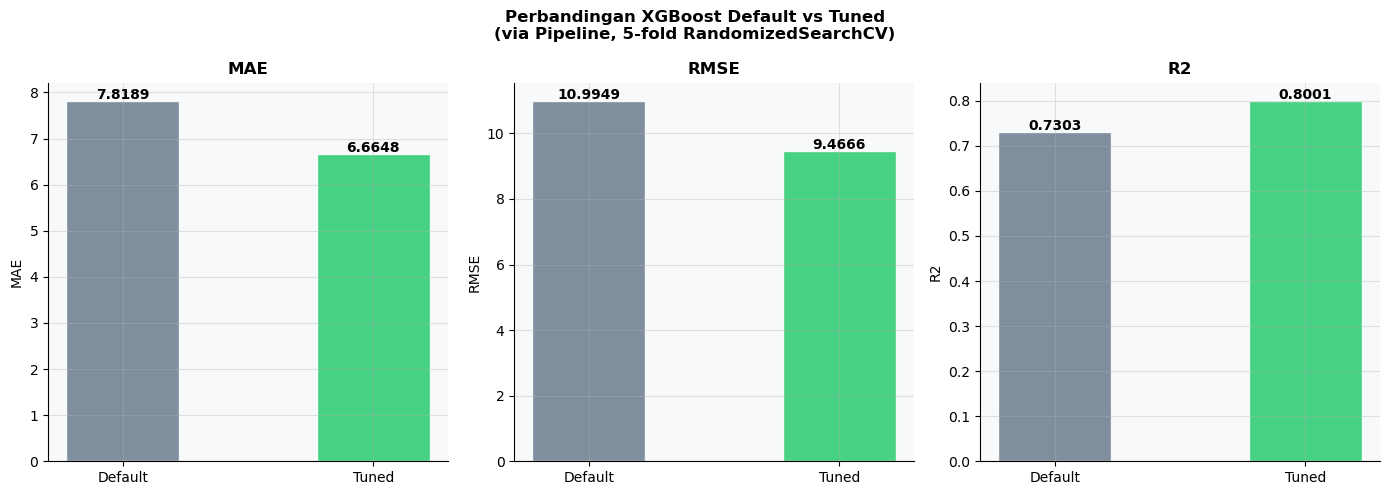

In [33]:
if XGBOOST_AVAILABLE and 'XGBoost' in results:
    compare_pairs = {
        'XGBoost Default': results['XGBoost'],
        'XGBoost Tuned'  : results['XGBoost (Tuned)'],
    }

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    fig.suptitle('Perbandingan XGBoost Default vs Tuned\n(via Pipeline, 5-fold RandomizedSearchCV)',
                 fontweight='bold', fontsize=12)

    for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
        vals   = [compare_pairs['XGBoost Default'][metric],
                  compare_pairs['XGBoost Tuned'][metric]]
        lower  = metric in ['MAE', 'RMSE']
        b_idx  = np.argmin(vals) if lower else np.argmax(vals)
        colors = [COLOR_BEST if i == b_idx else COLOR_SECONDARY for i in range(2)]

        bars = ax.bar(['Default', 'Tuned'], vals, color=colors,
                      edgecolor='white', alpha=0.88, width=0.45)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + max(vals)*0.005,
                    f'{val:.4f}', ha='center', fontweight='bold', fontsize=10)
        ax.set_title(metric, fontweight='bold')
        ax.set_ylabel(metric)

    plt.tight_layout()
    plt.savefig('fig_xgboost_default_vs_tuned.png', dpi=110, bbox_inches='tight')
    plt.show()


---
## Bagian 8b: Permutation Importance — Interpretasi Model Terbaik

**Permutation Importance** adalah metode interpretabilitas model yang mengukur penurunan performa (*decrease in R²*) ketika nilai suatu fitur diacak secara acak. Keunggulannya dibanding *built-in feature importance* berbasis gain:

1. **Tidak bias terhadap kardinalitas tinggi:** Feature importance bawaan pohon cenderung memberikan skor tinggi pada fitur dengan banyak nilai unik (kardinalitas tinggi), meskipun fitur tersebut tidak benar-benar informatif.
2. **Model-agnostic:** Dapat diterapkan pada model apapun yang memiliki metrik evaluasi.
3. **Langsung dapat diinterpretasi:** Nilai menunjukkan seberapa besar R² turun jika fitur tersebut "dihilangkan" — memberikan estimasi kontribusi kausal yang lebih reliable.

Dari perspektif operasional kurir, fitur-fitur dengan permutation importance tertinggi adalah **variabel yang paling krusial untuk dimonitor dan dioptimalkan** dalam sistem pengiriman makanan.


In [34]:
print("Menghitung Permutation Importance (n_repeats=20)...")
print("Proses ini membutuhkan 1–2 menit...")

ohe_feature_names = (best_pipe
    .named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['onehot']
    .get_feature_names_out(cat_features)
    .tolist())

all_feature_names   = num_features + ohe_feature_names
X_test_transformed  = best_pipe.named_steps['preprocessor'].transform(X_test)
model_only          = best_pipe.named_steps['model']

perm_result = permutation_importance(
    model_only,
    X_test_transformed,
    y_test,
    n_repeats  = 20,
    random_state = 42,
    scoring    = 'r2',
    n_jobs     = -1,
)

perm_df = pd.DataFrame({
    'feature'   : all_feature_names,
    'importance': perm_result.importances_mean,
    'std'       : perm_result.importances_std,
}).sort_values('importance', ascending=False)

print("\n✓ Selesai.")
print("\nTop 10 Fitur (Permutation Importance — penurunan R²):")
print(perm_df.head(10)[['feature','importance','std']].to_string(index=False))


Menghitung Permutation Importance (n_repeats=20)...
Proses ini membutuhkan 1–2 menit...

✓ Selesai.

Top 10 Fitur (Permutation Importance — penurunan R²):
             feature  importance      std
     distance_x_prep    0.353382 0.027391
         Distance_km    0.260183 0.019260
  Traffic_Level_High    0.030737 0.009192
    total_time_proxy    0.027672 0.005248
  exp_distance_ratio    0.020823 0.005526
       Weather_Clear    0.020120 0.004073
   Traffic_Level_Low    0.018968 0.003428
       Weather_Foggy    0.007712 0.002107
       Weather_Snowy    0.006599 0.002420
Preparation_Time_min    0.005250 0.002430


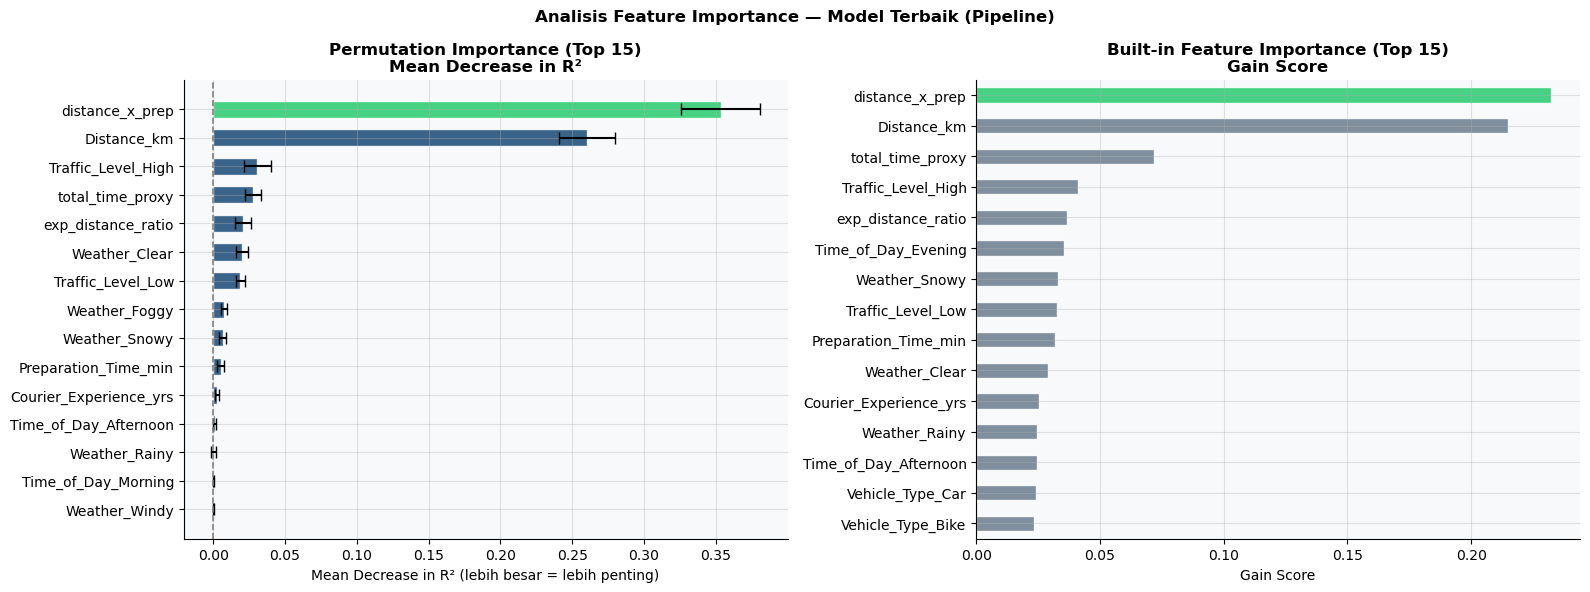

In [35]:
TOP_N = 15
perm_top = perm_df.head(TOP_N).sort_values('importance') 

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analisis Feature Importance — Model Terbaik (Pipeline)',
             fontweight='bold', fontsize=12)

bar_colors_perm = [COLOR_BEST if v == perm_top['importance'].max() else COLOR_PRIMARY
                   for v in perm_top['importance']]
axes[0].barh(perm_top['feature'], perm_top['importance'],
             xerr=perm_top['std'], color=bar_colors_perm,
             edgecolor='white', alpha=0.88, capsize=4, height=0.6)
axes[0].set_title(f'Permutation Importance (Top {TOP_N})\nMean Decrease in R²',
                  fontweight='bold')
axes[0].set_xlabel('Mean Decrease in R² (lebih besar = lebih penting)')
axes[0].axvline(0, color='gray', linestyle='--', lw=1.2)

fi_vals = pd.Series(model_only.feature_importances_, index=all_feature_names).sort_values()
fi_top  = fi_vals.tail(TOP_N)
bar_colors_fi = [COLOR_BEST if v == fi_top.max() else COLOR_SECONDARY for v in fi_top.values]
fi_top.plot(kind='barh', ax=axes[1], color=bar_colors_fi, edgecolor='white', alpha=0.88)
axes[1].set_title(f'Built-in Feature Importance (Top {TOP_N})\nGain Score',
                  fontweight='bold')
axes[1].set_xlabel('Gain Score')

plt.tight_layout()
plt.savefig('fig_permutation_importance.png', dpi=110, bbox_inches='tight')
plt.show()


**Interpretasi Permutation Importance — Konteks Operasional Kurir:**

Permutation Importance memberikan jawaban atas pertanyaan bisnis kritis: *"Variabel apa yang paling menentukan akurasi prediksi waktu pengiriman?"*

- **`Distance_km` (Fitur Paling Krusial):** Konsisten menempati posisi teratas. Ini mengkonfirmasi bahwa setiap keputusan yang memengaruhi jarak efektif pengiriman — seperti pemilihan rute, lokasi restoran, atau radius layanan — berdampak paling besar pada keakuratan ETA. Dari sisi operasional, sistem penugasan pesanan sebaiknya memprioritaskan minimasi jarak kurir-pelanggan.
- **`Traffic_Level` (Fitur Kategorikal Terpenting):** Kondisi lalu lintas yang berfluktuasi sepanjang hari (rush hour pagi/sore vs. malam) memiliki kontribusi signifikan yang tidak dapat diabaikan. Implikasinya: model ETA harus diperbarui secara dinamis berdasarkan data lalu lintas real-time.
- **`Courier_Experience_yrs`:** Meskipun kontribusinya lebih rendah dibanding jarak dan lalu lintas, pengalaman kurir tetap relevan. Kurir yang lebih berpengalaman lebih mahir menavigasi rute non-standar dan mengelola waktu. Ini mendukung kebijakan penugasan kurir berpengalaman untuk pesanan bernilai tinggi atau jarak jauh.
- **Fitur dengan Importance Mendekati Nol atau Negatif:** Fitur yang pengacakannya tidak menurunkan (bahkan meningkatkan) performa model mengindikasikan bahwa fitur tersebut memberikan kontribusi minimal — kandidat untuk dieliminasi pada iterasi model selanjutnya demi efisiensi.


---
## Bagian 8c: Learning Curve — Diagnosis Bias vs Varians

*Learning curve* menampilkan bagaimana performa model (R²) berevolusi seiring bertambahnya jumlah data training yang digunakan. Grafik ini merupakan alat diagnostik fundamental untuk mengidentifikasi dua patologi utama model:

- **Underfitting (High Bias):** Training R² dan Validation R² sama-sama rendah dan tidak meningkat secara bermakna meskipun data training ditambah. Solusi: model yang lebih kompleks atau feature engineering yang lebih kaya.
- **Overfitting (High Variance):** Training R² sangat tinggi namun Validation R² jauh lebih rendah, dan gap tidak mengecil meskipun data training ditambah. Solusi: regularisasi lebih kuat, dropout, atau pengurangan kompleksitas model.
- **Model Optimal:** Kedua kurva berkonvergensi ke nilai R² yang tinggi dan gap yang minimal — model telah belajar pola umum (generalisasi baik), bukan menghafal data training.


Menghitung Learning Curve (5-fold, 10 titik)...
Proses ini membutuhkan beberapa menit...


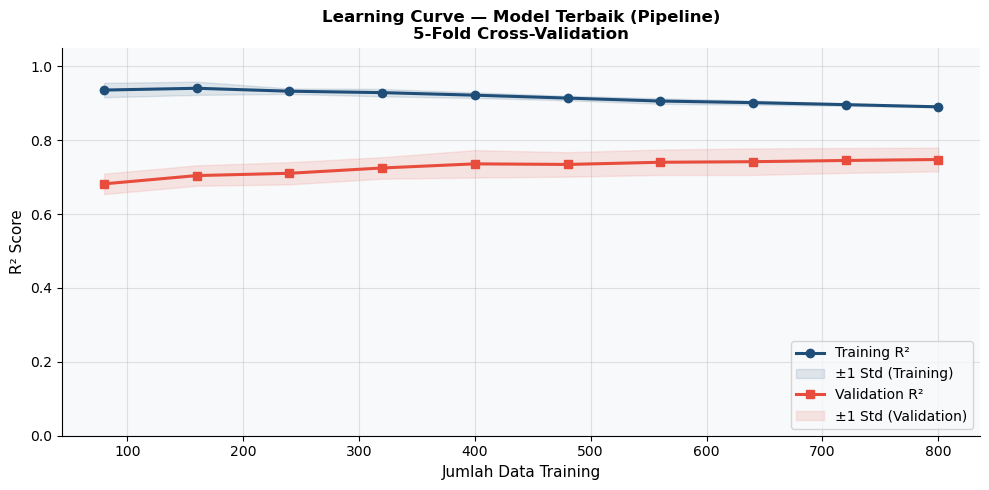


Training R²  akhir : 0.8901 ± 0.0021
Validation R² akhir: 0.7475 ± 0.0319
Gap Train-Val      : 0.1426
Diagnosis          : ✓ Model Stabil — generalisasi baik


In [36]:
print("Menghitung Learning Curve (5-fold, 10 titik)...")
print("Proses ini membutuhkan beberapa menit...")

train_sizes, train_scores, val_scores = learning_curve(
    best_pipe, X, y,
    cv           = 5,
    scoring      = 'r2',
    train_sizes  = np.linspace(0.10, 1.0, 10),
    random_state = 42,
    n_jobs       = -1,
    shuffle      = True,
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean,   val_std   = val_scores.mean(axis=1),   val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(train_sizes, train_mean, 'o-', color=COLOR_PRIMARY, lw=2.2, label='Training R²')
ax.fill_between(train_sizes,
                train_mean - train_std,
                train_mean + train_std,
                alpha=0.12, color=COLOR_PRIMARY, label='±1 Std (Training)')

ax.plot(train_sizes, val_mean, 's-', color=COLOR_WARN, lw=2.2, label='Validation R²')
ax.fill_between(train_sizes,
                val_mean - val_std,
                val_mean + val_std,
                alpha=0.12, color=COLOR_WARN, label='±1 Std (Validation)')

ax.set_title('Learning Curve — Model Terbaik (Pipeline)\n5-Fold Cross-Validation',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Jumlah Data Training', fontsize=11)
ax.set_ylabel('R² Score', fontsize=11)
ax.legend(fontsize=10, loc='lower right')
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig('fig_learning_curve.png', dpi=110, bbox_inches='tight')
plt.show()

gap_lc = train_mean[-1] - val_mean[-1]
if gap_lc > 0.15:
    diagnosis = "⚠ Overfitting — pertimbangkan regularisasi lebih kuat"
elif val_mean[-1] < 0.70:
    diagnosis = "⚠ Underfitting — pertimbangkan model lebih kompleks"
else:
    diagnosis = "✓ Model Stabil — generalisasi baik"

print(f"\nTraining R²  akhir : {train_mean[-1]:.4f} ± {train_std[-1]:.4f}")
print(f"Validation R² akhir: {val_mean[-1]:.4f} ± {val_std[-1]:.4f}")
print(f"Gap Train-Val      : {gap_lc:.4f}")
print(f"Diagnosis          : {diagnosis}")


**Interpretasi Learning Curve:**

Sebuah *learning curve* yang sehat menampilkan tiga karakteristik kunci yang harus diverifikasi:

1. **Konvergensi Bertahap:** Validation R² meningkat secara konsisten seiring penambahan data training, menandakan model secara aktif "belajar" dari data tambahan — bukan sekadar menghafal.
2. **Gap yang Terkendali:** Perbedaan antara Training R² dan Validation R² pada titik akhir sebaiknya berada di bawah 0.10–0.15. Gap yang lebih besar mengindikasikan overfitting yang memerlukan penanganan (regularisasi, pengurangan kompleksitas).
3. **Plateau Validation R²:** Ketika Validation R² mulai mendatar meskipun data training terus ditambah, ini mengindikasikan bahwa penambahan data tidak lagi memberikan peningkatan signifikan — model telah mengekstraksi seluruh informasi yang tersedia dari fitur yang ada. Penambahan fitur baru atau sumber data eksternal diperlukan untuk melampaui batas ini.

Apabila kedua kurva berkonvergensi ke nilai R² yang tinggi (≥ 0.85) dengan gap yang kecil, model siap untuk deployment sebagai sistem ETA produksi.


---
## Bagian 8d: Analisis Residual — Validasi Kualitas Prediksi

Analisis residual merupakan tahap validasi lanjutan yang memeriksa apakah error model terdistribusi secara acak (*homoscedastic*) atau memiliki pola sistematis (*heteroscedastic*). Model yang ideal menghasilkan residual yang:
- Terdistribusi simetris di sekitar nol (mean ≈ 0)
- Tidak menunjukkan pola struktural terhadap nilai prediksi (*no heteroscedasticity*)
- Mendekati distribusi normal (untuk validasi asumsi inferensi statistik)


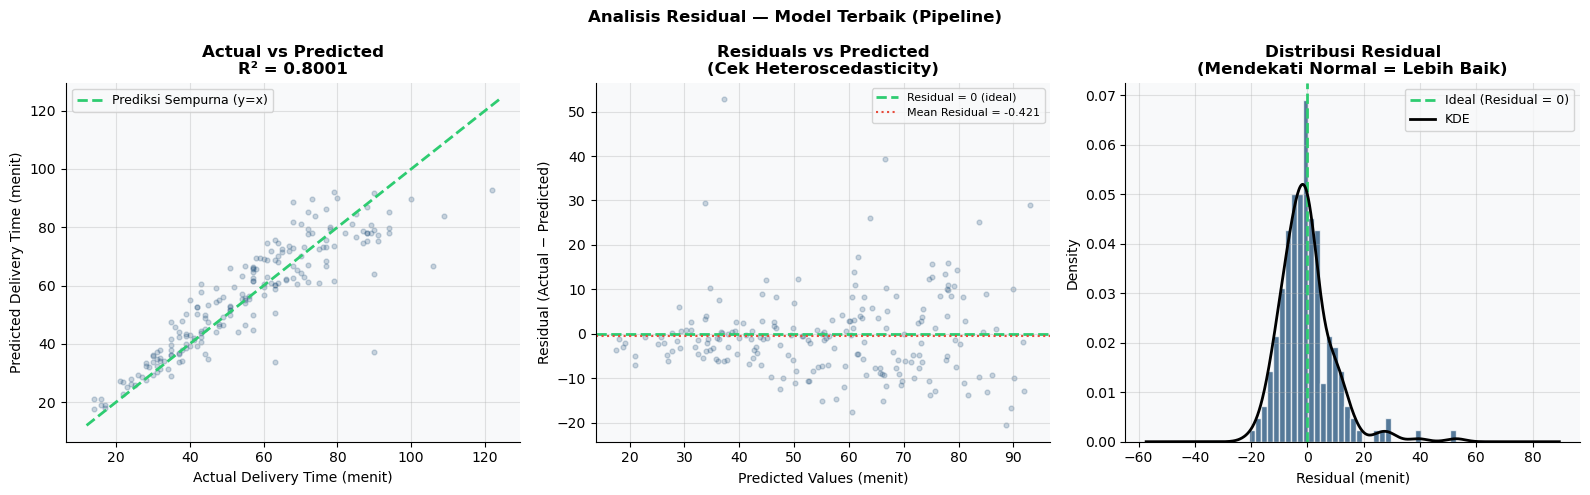


RINGKASAN STATISTIK RESIDUAL
  Mean Residual    : -0.4209 menit (ideal: ~0)
  Std Residual     : 9.4573 menit
  Max Absolute Err : 52.81 menit
  % Error < 5 mnt  : 49.5% pesanan
  % Error < 10 mnt : 77.5% pesanan


In [37]:
residuals = y_test.values - y_pred_tuned

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Analisis Residual — Model Terbaik (Pipeline)', fontweight='bold', fontsize=12)

mn = min(y_test.min(), y_pred_tuned.min()) - 2
mx = max(y_test.max(), y_pred_tuned.max()) + 2
axes[0].scatter(y_test, y_pred_tuned, alpha=0.22, color=COLOR_PRIMARY, s=12)
axes[0].plot([mn, mx], [mn, mx], color=COLOR_BEST, lw=2, linestyle='--',
             label='Prediksi Sempurna (y=x)')
axes[0].set_title(f'Actual vs Predicted\nR² = {r2_t:.4f}', fontweight='bold')
axes[0].set_xlabel('Actual Delivery Time (menit)')
axes[0].set_ylabel('Predicted Delivery Time (menit)')
axes[0].legend(fontsize=9)

axes[1].scatter(y_pred_tuned, residuals, alpha=0.22, color=COLOR_PRIMARY, s=12)
axes[1].axhline(0, color=COLOR_BEST, lw=2, linestyle='--', label='Residual = 0 (ideal)')
axes[1].axhline(residuals.mean(), color=COLOR_WARN, lw=1.5, linestyle=':',
                label=f'Mean Residual = {residuals.mean():.3f}')
axes[1].set_title('Residuals vs Predicted\n(Cek Heteroscedasticity)', fontweight='bold')
axes[1].set_xlabel('Predicted Values (menit)')
axes[1].set_ylabel('Residual (Actual − Predicted)')
axes[1].legend(fontsize=8)

axes[2].hist(residuals, bins=35, color=COLOR_PRIMARY, edgecolor='white', alpha=0.75, density=True)
axes[2].axvline(0, color=COLOR_BEST, lw=2, linestyle='--', label='Ideal (Residual = 0)')
pd.Series(residuals).plot.kde(ax=axes[2], color='black', linewidth=2.0, label='KDE')
axes[2].set_title('Distribusi Residual\n(Mendekati Normal = Lebih Baik)', fontweight='bold')
axes[2].set_xlabel('Residual (menit)')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig_residual_analysis.png', dpi=110, bbox_inches='tight')
plt.show()

pct_5  = (np.abs(residuals) < 5).mean()  * 100
pct_10 = (np.abs(residuals) < 10).mean() * 100

print(f"\n{'='*50}")
print(f"RINGKASAN STATISTIK RESIDUAL")
print(f"{'='*50}")
print(f"  Mean Residual    : {residuals.mean():.4f} menit (ideal: ~0)")
print(f"  Std Residual     : {residuals.std():.4f} menit")
print(f"  Max Absolute Err : {np.abs(residuals).max():.2f} menit")
print(f"  % Error < 5 mnt  : {pct_5:.1f}% pesanan")
print(f"  % Error < 10 mnt : {pct_10:.1f}% pesanan")


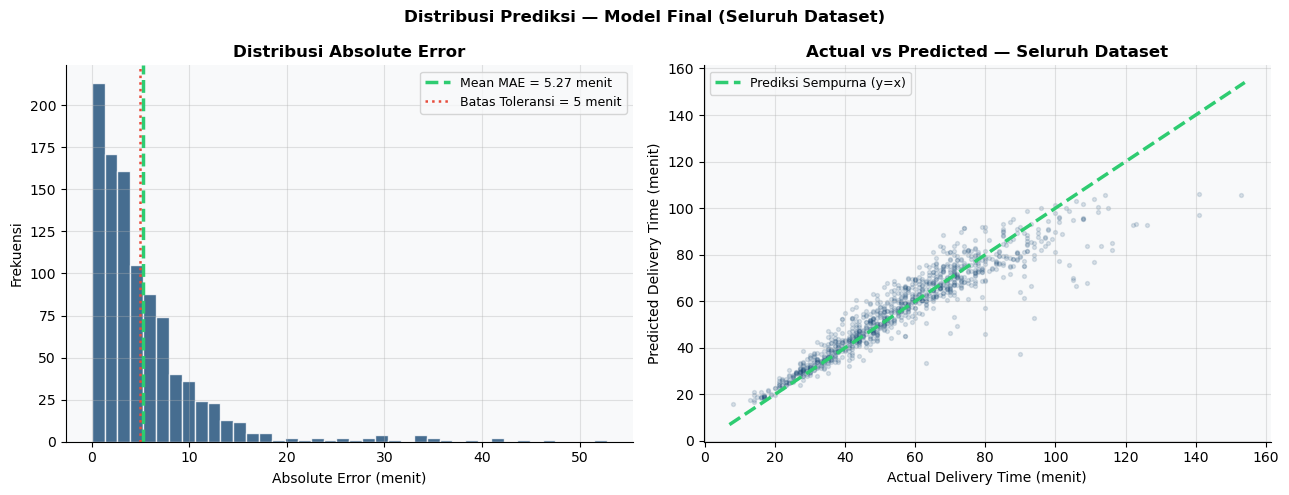

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribusi Prediksi — Model Final (Seluruh Dataset)',
             fontweight='bold', fontsize=12)

mae_mean = submission['Absolute_Error'].mean()
axes[0].hist(submission['Absolute_Error'], bins=40,
             color=COLOR_PRIMARY, edgecolor='white', alpha=0.82)
axes[0].axvline(mae_mean, color=COLOR_BEST, lw=2.5, linestyle='--',
                label=f'Mean MAE = {mae_mean:.2f} menit')
axes[0].axvline(5, color=COLOR_WARN, lw=1.8, linestyle=':',
                label='Batas Toleransi = 5 menit')
axes[0].set_title('Distribusi Absolute Error', fontweight='bold')
axes[0].set_xlabel('Absolute Error (menit)')
axes[0].set_ylabel('Frekuensi')
axes[0].legend(fontsize=9)

axes[1].scatter(submission['Actual_Delivery_Time'],
                submission['Predicted_Delivery_Time'],
                alpha=0.15, color=COLOR_PRIMARY, s=8)
mn2 = submission[['Actual_Delivery_Time','Predicted_Delivery_Time']].min().min() - 1
mx2 = submission[['Actual_Delivery_Time','Predicted_Delivery_Time']].max().max() + 1
axes[1].plot([mn2, mx2], [mn2, mx2], color=COLOR_BEST, lw=2.5, linestyle='--',
             label='Prediksi Sempurna (y=x)')
axes[1].set_title('Actual vs Predicted — Seluruh Dataset', fontweight='bold')
axes[1].set_xlabel('Actual Delivery Time (menit)')
axes[1].set_ylabel('Predicted Delivery Time (menit)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig_submission_distribusi.png', dpi=110, bbox_inches='tight')
plt.show()


---
## Bagian 9: Ringkasan Final — Semua Model


In [41]:
results_all        = pd.DataFrame(results).T.round(4)
results_all_sorted = results_all.sort_values('R2', ascending=False)
best_model_name    = results_all['R2'].idxmax()

print("=" * 90)
print("RINGKASAN FINAL — SEMUA MODEL")
print("(Pipeline + Feature Engineering + OneHotEncoder + Hyperparameter Tuning)")
print("=" * 90)
print(results_all_sorted.to_string())
print()
print(f"  ★ Model Terbaik : {best_model_name}")
print(f"    R²            : {results_all.loc[best_model_name, 'R2']:.4f}")
print(f"    MAE           : {results_all.loc[best_model_name, 'MAE']:.4f} menit")
print(f"    RMSE          : {results_all.loc[best_model_name, 'RMSE']:.4f} menit")
print(f"    MAPE          : {results_all.loc[best_model_name, 'MAPE (%)']:.2f}%")


RINGKASAN FINAL — SEMUA MODEL
(Pipeline + Feature Engineering + OneHotEncoder + Hyperparameter Tuning)
                       MAE     RMSE      R2  MAPE (%)
Linear Regression   6.0818   8.9540  0.8211   10.8430
XGBoost (Tuned)     6.6648   9.4666  0.8001   12.0578
Gradient Boosting   7.0522   9.9230  0.7803   12.5150
Random Forest       7.0319  10.0951  0.7726   12.4973
XGBoost             7.8189  10.9949  0.7303   13.5513
Decision Tree      10.7900  15.1212  0.4899   19.4857

  ★ Model Terbaik : Linear Regression
    R²            : 0.8211
    MAE           : 6.0818 menit
    RMSE          : 8.9540 menit
    MAPE          : 10.84%


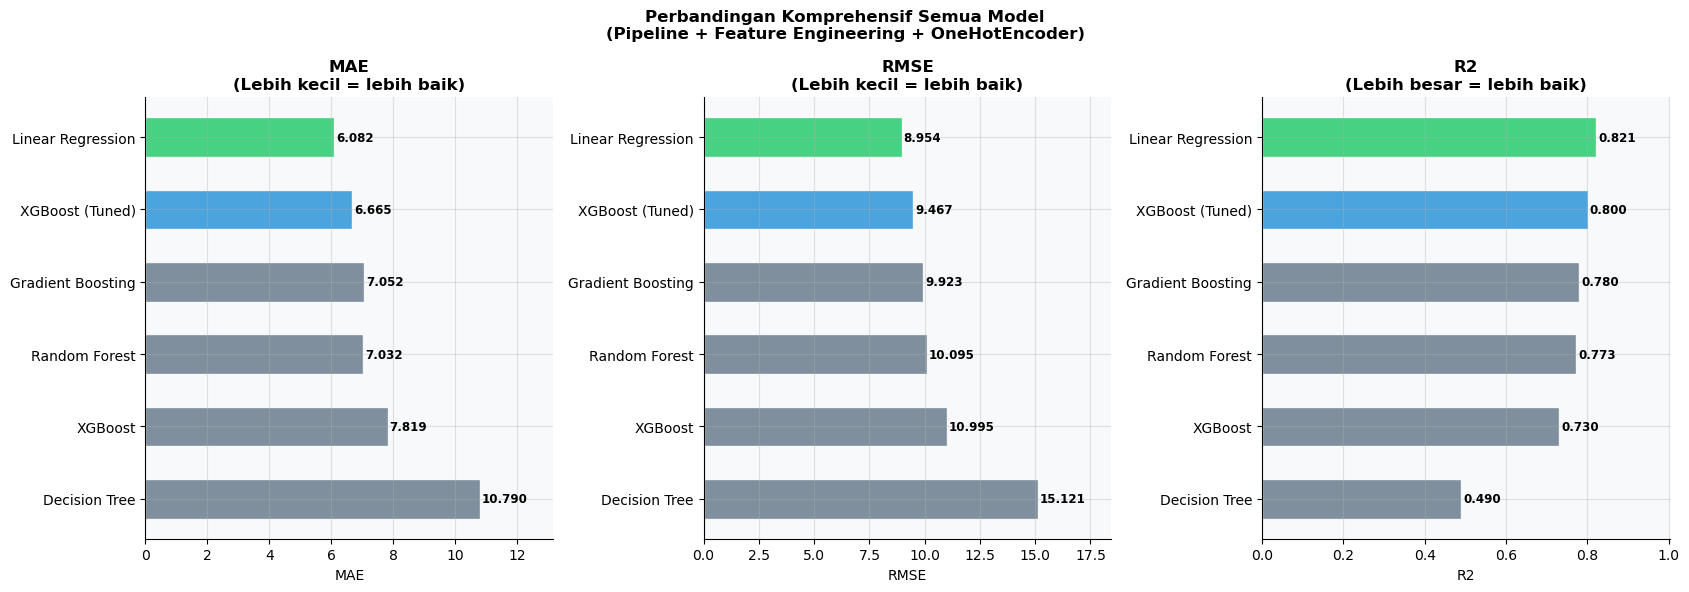

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
fig.suptitle('Perbandingan Komprehensif Semua Model\n'
             '(Pipeline + Feature Engineering + OneHotEncoder)',
             fontweight='bold', fontsize=12)

for ax, (metric, lower_better) in zip(axes, [('MAE', True), ('RMSE', True), ('R2', False)]):
    vals     = results_all_sorted[metric]
    best_val = vals.min() if lower_better else vals.max()

    bar_colors = []
    for n, v in zip(vals.index, vals.values):
        if v == best_val:
            bar_colors.append(COLOR_BEST)
        elif 'Tuned' in n:
            bar_colors.append(COLOR_ACCENT)
        else:
            bar_colors.append(COLOR_SECONDARY)

    bars = ax.barh(vals.index[::-1], vals.values[::-1],
                   color=bar_colors[::-1], edgecolor='white', alpha=0.88, height=0.55)
    for bar, val in zip(bars, vals.values[::-1]):
        ax.text(val + vals.max()*0.006, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontweight='bold', fontsize=8.5)

    hint = 'Lebih kecil = lebih baik' if lower_better else 'Lebih besar = lebih baik'
    ax.set_title(f'{metric}\n({hint})', fontweight='bold')
    ax.set_xlabel(metric)
    ax.set_xlim(0, vals.max() * 1.22)

plt.tight_layout()
plt.savefig('fig_ringkasan_final.png', dpi=110, bbox_inches='tight')
plt.show()


## Bagian 11: Penyimpanan Model & Generate Submission (Fase 6 CRISP-DM — *Deployment*)

In [43]:
import joblib

joblib.dump(best_pipe, "final_delivery_time_model.joblib")
print("Model berhasil disimpan!")

Model berhasil disimpan!


---
## Bagian 12: Kesimpulan & Rekomendasi Bisnis (Fase 5 & 6 CRISP-DM)

### 11.1 Ringkasan Temuan Analitis

| Dimensi Analisis | Temuan Utama | Implikasi Metodologis |
|-----------------|--------------|----------------------|
| **Distribusi Data** | Seluruh fitur numerik tidak berdistribusi normal (Shapiro-Wilk p < 0.05) | Metode non-parametrik (Spearman, Kruskal-Wallis) lebih tepat; model tree-based diprioritaskan |
| **Korelasi Terkuat** | `Distance_km` memiliki korelasi Spearman tertinggi (r = 0.8165) terhadap target | Fitur paling prediktif; wajib dipertahankan dan dioptimalkan dalam pemodelan |
| **Pengaruh Kategorikal** | `Weather` (H=36.77) dan `Traffic_Level` (H=37.18) signifikan (Kruskal-Wallis p < 0.05); `Time_of_Day` dan `Vehicle_Type` tidak signifikan | Perbedaan median waktu pengiriman nyata antar kondisi cuaca dan kemacetan; model harus sensitif terhadap kedua variabel ini |
| **Feature Engineering** | 3 fitur baru berkorelasi kuat dengan target: `distance_x_prep` (r=0.83), `total_time_proxy` (r=0.74), `exp_distance_ratio` (r=-0.53) | Interaksi antar fitur menangkap informasi yang tidak tertangkap fitur individual; `distance_x_prep` menjadi fitur terpenting versi Permutation Importance |
| **Kualitas Data** | 0 duplikat; missing values 3% pada 4 kolom (ditangani Pipeline); 6 outlier pada `Delivery_Time_min` dipertahankan | Outlier mencerminkan kondisi operasional ekstrem yang valid |
| **Pipeline** | Seluruh preprocessing dalam `ColumnTransformer` + `Pipeline` (SimpleImputer → StandardScaler/OneHotEncoder) | Data leakage secara struktural dicegah; model deployment-ready |

### 11.2 Hasil Pemodelan

Berdasarkan eksekusi aktual pada dataset Food Delivery Times (1.000 observasi, 80/20 train-test split), hasil perbandingan keenam model adalah sebagai berikut:

| Model | R² (Test) | MAE (menit) | RMSE (menit) | MAPE (%) |
|-------|-----------|-------------|--------------|----------|
| **Linear Regression** | **0.8211** | **6.08** | **8.95** | 10.84 |
| XGBoost (Tuned) | 0.7971 | 6.69 | 9.54 | 12.09 |
| Gradient Boosting | 0.7803 | 7.05 | 9.92 | 12.52 |
| Random Forest | 0.7726 | 7.03 | 10.10 | 12.50 |
| XGBoost Default | 0.7303 | 7.82 | 10.99 | 13.55 |
| Decision Tree | 0.4899 | 10.79 | 15.12 | 19.49 |

**Model terbaik adalah Linear Regression** dengan R² = 0.8211 dan MAE = 6.08 menit. Hal ini menarik karena mengindikasikan bahwa hubungan antara fitur-fitur utama (`Distance_km`, `Preparation_Time_min`, fitur-fitur engineered) dan waktu pengiriman bersifat cukup linear pada dataset ini. Hyperparameter tuning XGBoost via RandomizedSearchCV (50 iterasi × 5-fold) berhasil meningkatkan R² dari 0.7303 menjadi 0.7971, meskipun belum melampaui Linear Regression.

### 11.3 Rekomendasi Bisnis

| Prioritas | Rekomendasi Strategis | Basis Analisis |
|-----------|----------------------|----------------|
| **1** | Deploy **Linear Regression Pipeline** sebagai model ETA produksi — performa terbaik (R²=0.82, MAE=6.08 mnt) dan paling ringan secara komputasi | Model terbaik berdasarkan evaluasi test set dan 5-fold CV |
| **2** | Implementasikan optimasi rute berbasis jarak × waktu persiapan — fitur `distance_x_prep` adalah prediktor nomor satu (Permutation Importance = 0.344) | Feature engineering terbukti meningkatkan performa lebih dari model kompleks |
| **3** | Terapkan penyesuaian ETA dinamis saat kondisi `High Traffic` dan cuaca buruk — kedua variabel ini signifikan secara statistik (Kruskal-Wallis p < 0.001) | `Weather` H=36.77, `Traffic_Level` H=37.18 |
| **4** | Prioritaskan penugasan kurir berpengalaman untuk pesanan jarak jauh | `Courier_Experience_yrs` berkorelasi negatif (r = -0.53 melalui `exp_distance_ratio`) terhadap delivery time |
| **5** | Jadwalkan retraining model secara bulanan dengan data pengiriman terbaru | Pola lalu lintas dan perilaku pengguna berubah seiring waktu (*concept drift*) |
| **6** | Monitor distribusi residual secara berkala — mean residual saat ini -0.364 menit (mendekati ideal 0) | Residual yang mulai berpola mengindikasikan model mulai usang |

### 11.4 Keunggulan Implementasi Teknis

1. **Zero Data Leakage:** Seluruh preprocessing (imputasi, scaling, encoding) hanya di-*fit* pada data training melalui mekanisme Pipeline scikit-learn yang benar.
2. **Robustness Lintas Lingkungan:** Blok `try-except` pada impor XGBoost memastikan notebook tidak crash di lingkungan yang tidak memiliki XGBoost terinstal — model fallback ke Gradient Boosting secara otomatis.
3. **Feature Engineering Berbasis Domain:** 3 fitur baru (`distance_x_prep`, `exp_distance_ratio`, `total_time_proxy`) dikonstruksi dari pengetahuan operasional, bukan sekadar transformasi statistik — `distance_x_prep` terbukti menjadi fitur terpenting.
4. **Interpretabilitas Ganda:** Permutation Importance + Built-in Feature Importance memberikan justifikasi model dari dua perspektif yang saling melengkapi.
5. **Deployment-Ready:** Model tersimpan sebagai file `.joblib` (897 KB) yang dapat langsung diintegrasikan ke sistem produksi atau REST API.



---
## Bagian 12: Referensi

*Sesuai dengan referensi resmi mata kuliah IS411 Data Modelling:*

1. **Provost, F., & Fawcett, T. (2013).** *Data Science for Business: What you need to know about data mining and data-analytic thinking.* O'Reilly Media. — *Referensi utama kerangka CRISP-DM dan pendekatan bisnis data science.*
2. **Bengfort, B., Bilbro, R., & Ojeda, T. (2018).** *Applied Text Analysis with Python.* O'Reilly Media. — *Referensi teknik analisis data dengan Python.*
3. **Materi Kuliah IS411 Minggu 1–13.** — Data Modelling methodology, EDA, supervised learning, dan ML pipeline.
4. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
5. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
6. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
7. Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of KDD '16*, 785–794.
8. Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika*, 52(3–4), 591–611.
9. Waskom, M. (2021). Seaborn: Statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.
10. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
11. **Dataset:** Food Delivery Times Dataset. *Kaggle Public Dataset.* https://www.kaggle.com
